In [8]:
from pathlib import Path
import re
import json 
import sys
import os

import matplotlib
import matplotlib.pyplot as plt
# %matplotlib notebook
%matplotlib inline
import numpy as np
import pandas as pd
import seaborn as sns  
import pickle as pkl
from tqdm import tqdm
from tensorboard.backend.event_processing import event_accumulator
from concurrent.futures import ThreadPoolExecutor
from concurrent.futures import as_completed

module_path = os.path.abspath(os.path.join('../'))
if module_path not in sys.path:
    sys.path.append(module_path)


In [9]:
tags = ["charts/episodic_return", "eval/mu"]
results_advtra = pkl.load(open('irm_pkl/160124_advtra_multickpt.pkl','rb'))
results_airl_pert = pkl.load(open('irm_pkl/050124_sac_pert.pkl','rb'))
results_airl_pert_2 = pkl.load(open('irm_pkl/080124_sac_500k_pert.pkl','rb'))
results_airl_pert_bm = pkl.load(open('irm_pkl/301223_bodymass.pkl','rb'))
results_advtra_clean = pkl.load(open('irm_pkl/2001_advtra_clean.pkl','rb'))
results_ll_pert = pkl.load(open('irm_pkl/2001_lunar_perturb.pkl','rb'))
results_clean_load_1 = pkl.load(open('irm_pkl/2201_clean_load.pkl','rb'))
results_clean_load_2 = pkl.load(open('irm_pkl/2301_clean_load_500k.pkl','rb'))
results_advtra_pert_airl = pkl.load(open('irm_pkl/2401_sac_airl_advtr_pert.pkl','rb'))


In [10]:
len(list(results_airl_pert.keys()))

1104

In [11]:
def process_results(envs, results, param_filter_key_list, param_filter_value_list, irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0], lip_coeffs=[0.0, 1.0, 10.0], seeds=[515, 234, 894, 322, 72], print_files=False, len_thr=None):
    # filter into airl, gail_lip
    d, d_mustd = {}, {}
    #envs = ['AdroitHandDoor-v1', 'AdroitHandPen-v1', 'FrankaKitchen-v1']

    for env_name in envs:
        d[env_name] = {}
        for seed in seeds:
            d[env_name][seed] = {}
            for irm_c in irm_coeffs:
                d[env_name][seed][irm_c]  = {}
                for lip_c in lip_coeffs:
                    d[env_name][seed][irm_c][lip_c]  = {}
                    
    
    for env_name in envs:
        d_mustd[env_name] = {}
        for irm_c in irm_coeffs:
            d_mustd[env_name][irm_c]  = {}
            for lip_c in lip_coeffs:
                d_mustd[env_name][irm_c][lip_c]  = {}
                
                
    # load results and filter them according to keyss
    for k, v in results.items():
        hparams = v[2]
        env_name = hparams['env_id']

        seed = int(hparams['seed'])
        irm_c = float(hparams['irm_coeff'])
        lip_c = float(hparams['lip_coeff'])
        if not v[2]:
            print("empty dict", k)


        if print_files:
            print(k)
            print(hparams['env_kwargs'])
            print(hparams['env_kwargs_values'])

        filter_list = []
        for k_hp, v_hp in zip(param_filter_key_list, param_filter_value_list):
            filter_list.append(hparams[k_hp] == v_hp)

        if all(filter_list):
            #print(env_name, seed, irm_c, lip_c)
            d[env_name][seed][irm_c][lip_c] = v
            
    # fill mu,std dict by averagin over seeds
    print("Computing mu/std")
    for env in envs:
        for irm_c in irm_coeffs:
            for lip_c in lip_coeffs:
                val_list = []
                min_len = 1000
                
                if len_thr is None:
                    if 'Humanoid' in env:
                        len_thresh = 80
                    else:
                        len_thresh = 90
                else:
                    len_thresh = len_thr

                #print(env, seed, irm_c, lip_c)
                #hparams = d[env][seed][irm_c][lip_c][2]
                #print(hparams['perturb_parameters'])
                for seed in seeds:
                    if(isinstance(d[env][seed][irm_c][lip_c],tuple)):                            
                        if len(d[env][seed][irm_c][lip_c][1]['Value']) >= len_thresh:
                            val_list.append(d[env][seed][irm_c][lip_c][1]['Value'][:len_thresh])
                        else:
                            print(f"Incomplete length: {hparams['exp_name']}", env, seed, irm_c, lip_c, len(d[env][seed][irm_c][lip_c][1]['Value']))
                    else:
                        print(f"Missing tuple for {env, seed, irm_c, lip_c}")

                if len(val_list) >= 3:
                    mu = np.mean(np.stack(val_list),0)
                    std = np.std(np.stack(val_list),0)
                else:
                    mu, std = np.zeros(len_thresh), np.zeros(len_thresh)

                d_mustd[env][irm_c][lip_c] = (mu, std)
    
    return d, d_mustd
                

### Set plot preferences

In [12]:
from matplotlib.lines import Line2D
from matplotlib.gridspec import GridSpec
fs_m1 = 7  # for figure ticks
fs = 8  # for regular figure text
fs_p1 = 10  # figure titles

axes_lw = 0.7

matplotlib.rc('font', size=fs)          # controls default text sizes
matplotlib.rc('axes', titlesize=fs)     # fontsize of the axes title
matplotlib.rc('axes', labelsize=fs)    # fontsize of the x and y labels
matplotlib.rc('axes', linewidth=axes_lw)    # fontsize of the x and y labels
matplotlib.rc('xtick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('ytick', labelsize=fs_m1)    # fontsize of the tick labels
matplotlib.rc('legend', fontsize=fs_m1)    # legend fontsize
matplotlib.rc('figure', titlesize=fs_p1)  # fontsize of the figure title

matplotlib.rc('font', **{'family': 'serif', 'serif': ['Times New Roman']})

matplotlib.rc('text', usetex=True)

plt.rcParams.update({'text.latex.preamble': r'\usepackage{amsfonts}'})

def remove_xticks(ax):
    for tick in ax.xaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.xaxis.set_tick_params(which='minor', bottom=False, top=False)
    ax.xaxis.set_tick_params(which='major', bottom=False, top=False)
    ax.set_xticklabels([])
        
def remove_yticks(ax):
    for tick in ax.yaxis.get_major_ticks():
        tick.tick1line.set_visible(False)
        tick.tick2line.set_visible(False)
    ax.yaxis.set_tick_params(which='minor', left=False)
    ax.set_yticklabels([])

def smooth_mu_std(mu, std, N=6):
    mu_s = np.convolve(mu, np.ones(N)/N, mode='valid')
    std_s = np.convolve(std, np.ones(N)/N, mode='valid')
    
    return mu_s, std_s


In [13]:
lins = ['--perturb_dynamics=0.1']
pps = ['jnt_range', 'actuator_ctrlrange', 'geom_friction']

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Computing mu/std
Missing tuple for ('Ant-v3', 515, 0.0, 0.0)
Missing tuple for ('Ant-v3', 234, 0.0, 0.0)
Missing tuple for ('Ant-v3', 894, 0.0, 0.0)
Missing tuple for ('Ant-v3', 322, 0.0, 0.0)
Missing tuple for ('Ant-v3', 72, 0.0, 0.0)
Incomplete length: sac_airl Ant-v3 515 0.1 0.0 89
Missing tuple for ('Walker2d-v3', 515, 0.0, 0.0)
Missing tuple for ('Walker2d-v3', 234, 0.0, 0.0)
Missing tuple for ('Walker2d-v3', 894, 0.0, 0.0)
Missing tuple for ('Walker2d-v3', 72, 0.0, 0.0)
Missing tuple for ('Walker2d-v3', 515, 0.1, 0.0)
Missing tuple for ('Walker2d-v3', 322, 0.1, 0.0)
Missing tuple for ('Walker2d-v3', 72, 0.1, 0.0)
Missing tuple for ('Walker2d-v3', 515, 1.0, 0.0)
Missing tuple for ('Walker2d-v3', 234, 1.0, 0.0)
Missing tuple for ('Walker2d-v3', 322, 1.0, 0.0)
Missing tuple for ('Walker2d-v3', 72, 1.0, 0.0)
Missing tuple for ('HalfCheetah-v3', 515, 0.0, 0.0)
Missing tuple for ('HalfCheetah-v3', 234, 0.0, 0.0)
Missing tuple for ('HalfCheetah-v3', 894, 0.0, 0.0)
Missing tuple for ('Ha

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

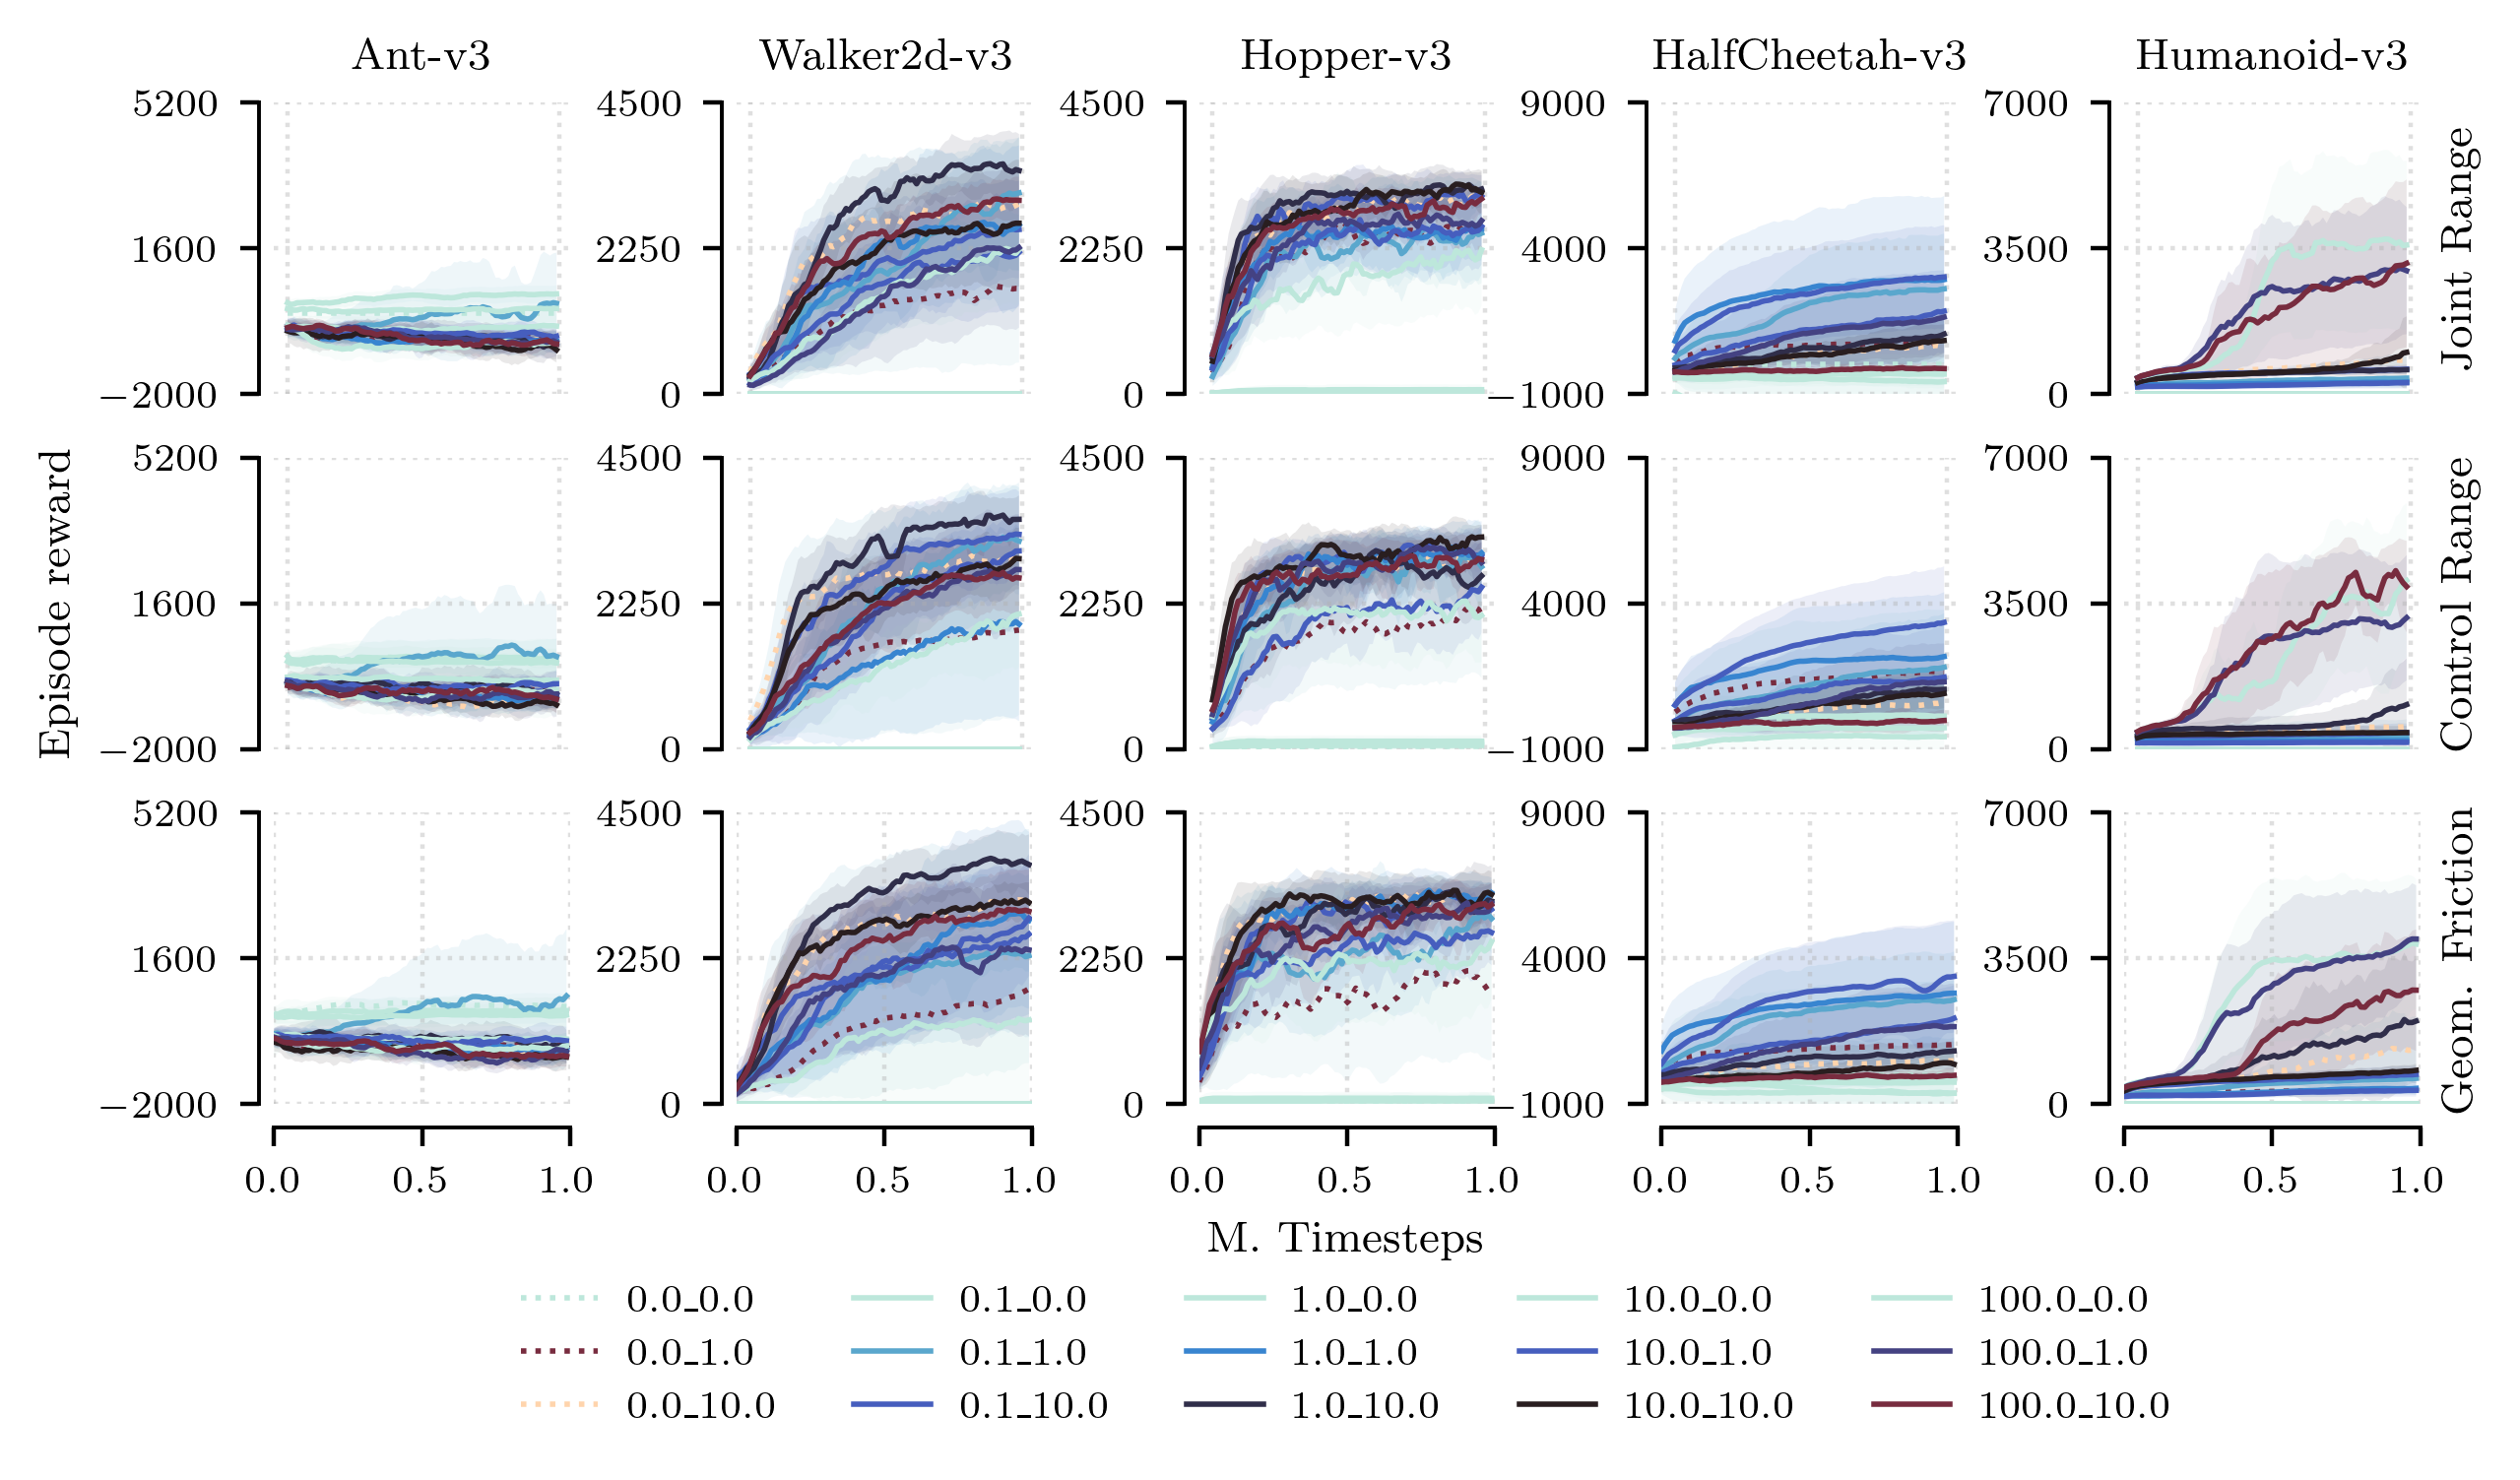

In [23]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

results_file = results_airl_pert_2

d_airl_jnt, d_airl_jnt_mustd = process_results(envs, results_file, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters'],param_filter_value_list=['True','sac_airl','0.1',"['jnt_range']"])
d_airl_ctrl, d_airl_ctrl_mustd = process_results(envs, results_file, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters'],param_filter_value_list=['True','sac_airl','0.1',"['actuator_ctrlrange']"])
d_airl_friction, d_airl_friction_mustd = process_results(envs, results_file, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters'],param_filter_value_list=['True','sac_airl','0.1',"['geom_friction']"])
d_mustds = {'airl+jnt': d_airl_jnt_mustd, 
            'airl+ctrl':d_airl_ctrl_mustd,
            'airl+friction':d_airl_friction_mustd}

irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
cm2 =sns.color_palette("inferno", as_cmap=True)

from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

text_width = 6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds),5, dpi=400, figsize=[text_width, 3])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")
            for j, env in enumerate(envs):
                # plot gail

                ax[i,j].set_prop_cycle('color', [cm(1.*(l*m+m)/NUM_COLORS) for i in range(NUM_COLORS)])

                ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)
                    
                #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    
                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.4, linestyle=':')
                
                # set env specific limits
                ax[i,0].set_ylim(-2000, 5200)
                ax[i,0].set_yticks([-2000, 1600, 5200])
                ax[i,1].set_ylim(0, 4500)
                ax[i,1].set_yticks([0, 2250, 4500])
                ax[i,2].set_ylim(0, 4500)
                ax[i,2].set_yticks([0, 2250, 4500])            
                ax[i,3].set_ylim(-1000, 9000)
                ax[i,3].set_yticks([-1000, 4000, 9000])                        
                ax[i,4].set_ylim(0, 7000)
                ax[i,4].set_yticks([0, 3500, 7000])                                          
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])

                
                mu,std = v[env][irm_c][lip_c]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if irm_c == 0.0:
                    ax[i,j].plot(x, mu,lw=1, label=f"{irm_c}_{lip_c}", linestyle=':', color=cm(2.*m/len(lip_coeffs)))
                else:
                    ax[i,j].plot(x, mu,lw=1, label=f"{irm_c}_{lip_c}")#, linestyle=next(linecycler)[-1])

                ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)
                
            ax[2,2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.5), fancybox=False, shadow=False, frameon=False, ncol=5)
            ax[2,2].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            ax[0,-1].set_ylabel("Joint Range", rotation=90)
            ax[1,-1].set_ylabel("Control Range", rotation=90)
            ax[2,-1].set_ylabel("Geom. Friction", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
#fig.savefig(f"fig_pert_200k.pdf", bbox_inches='tight', pad_inches=0.01)

### Load second dictionary (500k)

In [9]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

d_airl_jnt, d_airl_jnt_mustd = process_results(envs, results_airl_pert_2, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters'],param_filter_value_list=['True','sac_airl','0.1',"['jnt_range']"])
d_airl_ctrl, d_airl_ctrl_mustd = process_results(envs, results_airl_pert_2, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters'],param_filter_value_list=['True','sac_airl','0.1',"['actuator_ctrlrange']"])
d_airl_friction, d_airl_friction_mustd = process_results(envs, results_airl_pert_2, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics','perturb_parameters'],param_filter_value_list=['True','sac_airl','0.1',"['geom_friction']"])

Computing mu/std
Missing tuple for ('Ant-v3', 515, 0.0, 0.0)
Missing tuple for ('Ant-v3', 234, 0.0, 0.0)
Missing tuple for ('Ant-v3', 894, 0.0, 0.0)
Missing tuple for ('Ant-v3', 322, 0.0, 0.0)
Missing tuple for ('Ant-v3', 72, 0.0, 0.0)
Incomplete length: sac_airl Ant-v3 515 0.1 0.0 89
Missing tuple for ('Walker2d-v3', 515, 0.0, 0.0)
Missing tuple for ('Walker2d-v3', 234, 0.0, 0.0)
Missing tuple for ('Walker2d-v3', 894, 0.0, 0.0)
Missing tuple for ('Walker2d-v3', 72, 0.0, 0.0)
Missing tuple for ('Walker2d-v3', 515, 0.1, 0.0)
Missing tuple for ('Walker2d-v3', 322, 0.1, 0.0)
Missing tuple for ('Walker2d-v3', 72, 0.1, 0.0)
Missing tuple for ('Walker2d-v3', 515, 1.0, 0.0)
Missing tuple for ('Walker2d-v3', 234, 1.0, 0.0)
Missing tuple for ('Walker2d-v3', 322, 1.0, 0.0)
Missing tuple for ('Walker2d-v3', 72, 1.0, 0.0)
Missing tuple for ('HalfCheetah-v3', 515, 0.0, 0.0)
Missing tuple for ('HalfCheetah-v3', 234, 0.0, 0.0)
Missing tuple for ('HalfCheetah-v3', 894, 0.0, 0.0)
Missing tuple for ('Ha

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

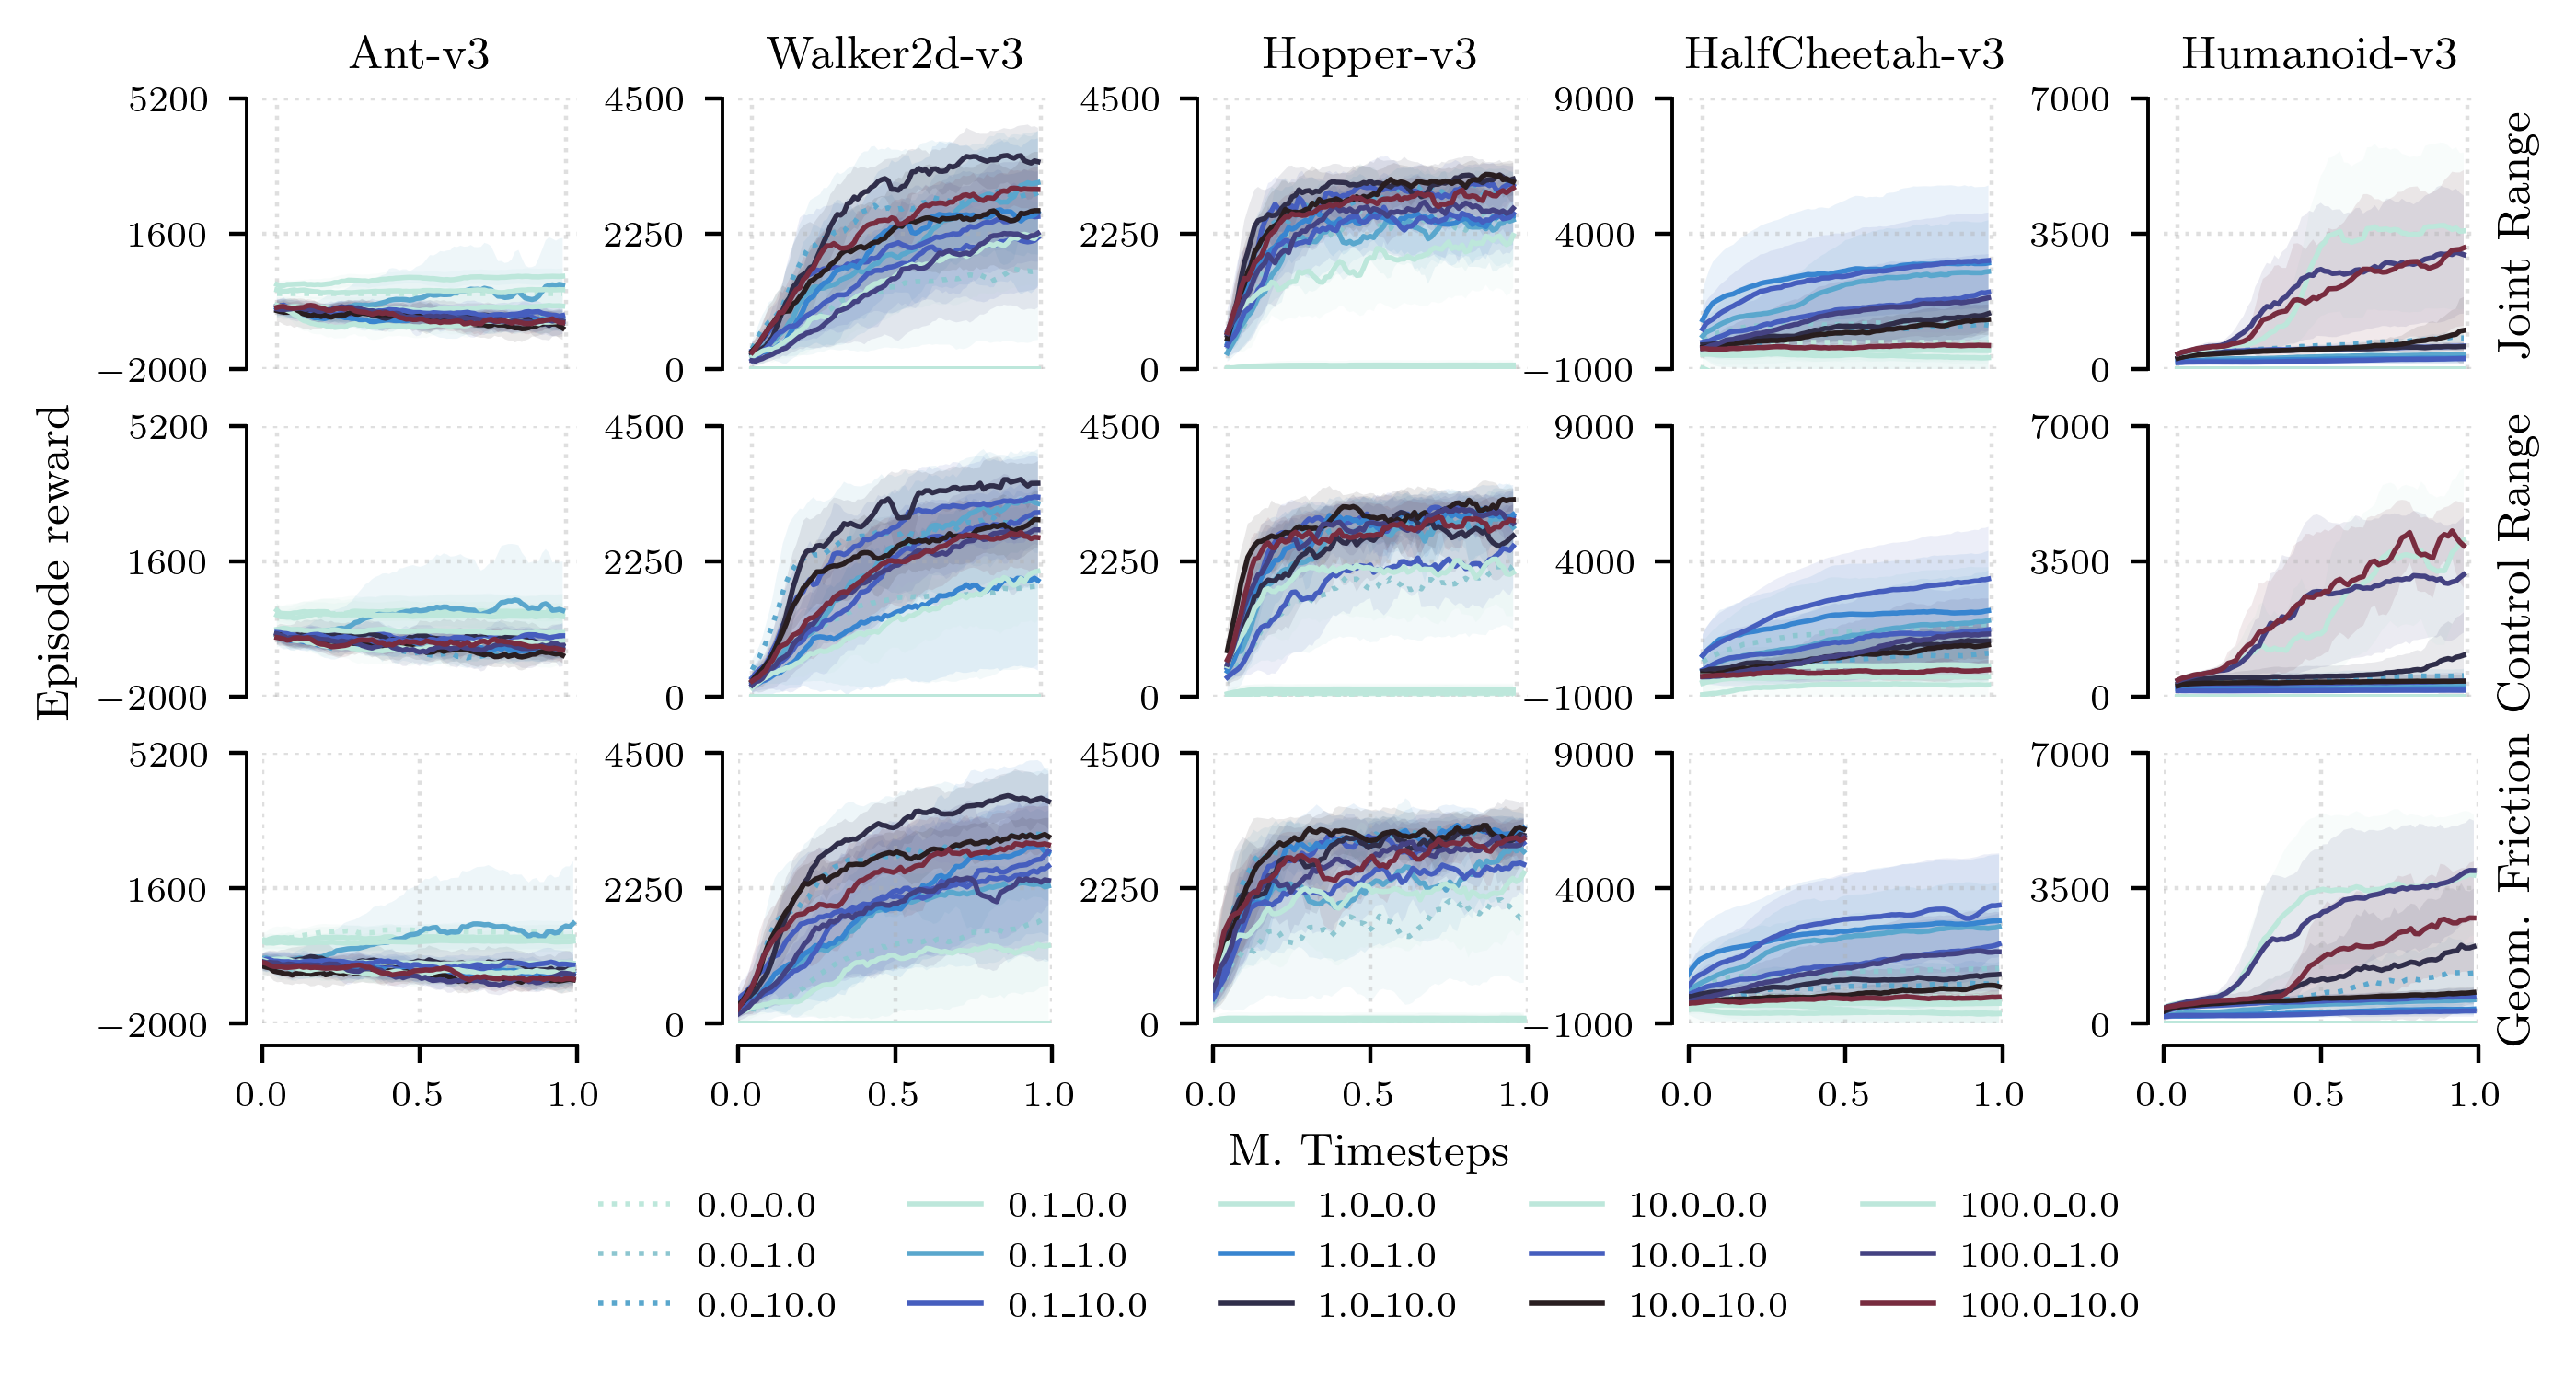

In [10]:

d_mustds = {'airl+jnt': d_airl_jnt_mustd, 
            'airl+ctrl':d_airl_ctrl_mustd,
            'airl+friction':d_airl_friction_mustd}

irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds),5, dpi=400, figsize=[text_width, 3])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")
            for j, env in enumerate(envs):
                # plot gail

                ax[i,j].set_prop_cycle('color', [cm(1.*(l*m+m)/NUM_COLORS) for i in range(NUM_COLORS)])

                ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)
                    
                #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    
                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.4, linestyle=':')
                
                # set env specific limits
                ax[i,0].set_ylim(-2000, 5200)
                ax[i,0].set_yticks([-2000, 1600, 5200])
                ax[i,1].set_ylim(0, 4500)
                ax[i,1].set_yticks([0, 2250, 4500])
                ax[i,2].set_ylim(0, 4500)
                ax[i,2].set_yticks([0, 2250, 4500])            
                ax[i,3].set_ylim(-1000, 9000)
                ax[i,3].set_yticks([-1000, 4000, 9000])                        
                ax[i,4].set_ylim(0, 7000)
                ax[i,4].set_yticks([0, 3500, 7000])                                          
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])

                
                mu,std = v[env][irm_c][lip_c]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if irm_c == 0.0:
                    ax[i,j].plot(x, mu,lw=1, label=f"{irm_c}_{lip_c}", linestyle=':')
                else:
                    ax[i,j].plot(x, mu,lw=1, label=f"{irm_c}_{lip_c}")#, linestyle=next(linecycler)[-1])

                ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)
                
            ax[2,2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.5), fancybox=False, shadow=False, frameon=False, ncol=5)
            ax[2,2].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            ax[0,-1].set_ylabel("Joint Range", rotation=90)
            ax[1,-1].set_ylabel("Control Range", rotation=90)
            ax[2,-1].set_ylabel("Geom. Friction", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
#fig.savefig(f"testfig1.pdf", bbox_inches='tight', pad_inches=0.01)

Computing mu/std
Incomplete length: sac_airl Ant-v3 515 0.0 0.0 52
Incomplete length: sac_airl Ant-v3 234 0.0 0.0 59
Incomplete length: sac_airl Ant-v3 894 0.0 0.0 61
Incomplete length: sac_airl Ant-v3 322 0.0 0.0 62
Incomplete length: sac_airl Ant-v3 515 0.0 1.0 88
Incomplete length: sac_airl Ant-v3 515 0.1 0.0 65
Incomplete length: sac_airl Ant-v3 234 0.1 0.0 60
Incomplete length: sac_airl Ant-v3 894 0.1 0.0 47
Incomplete length: sac_airl Ant-v3 322 0.1 0.0 52
Incomplete length: sac_airl Ant-v3 72 0.1 0.0 46
Incomplete length: sac_airl Ant-v3 515 1.0 0.0 54
Incomplete length: sac_airl Ant-v3 234 1.0 0.0 57
Incomplete length: sac_airl Ant-v3 894 1.0 0.0 57
Incomplete length: sac_airl Ant-v3 322 1.0 0.0 58
Incomplete length: sac_airl Ant-v3 72 1.0 0.0 54
Incomplete length: sac_airl Ant-v3 322 1.0 1.0 85
Incomplete length: sac_airl Ant-v3 515 10.0 0.0 57
Incomplete length: sac_airl Ant-v3 72 10.0 0.0 81
Incomplete length: sac_airl Walker2d-v3 515 0.0 0.0 34
Incomplete length: sac_airl W

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85


...

85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85
85
85
85
85
75
85
85


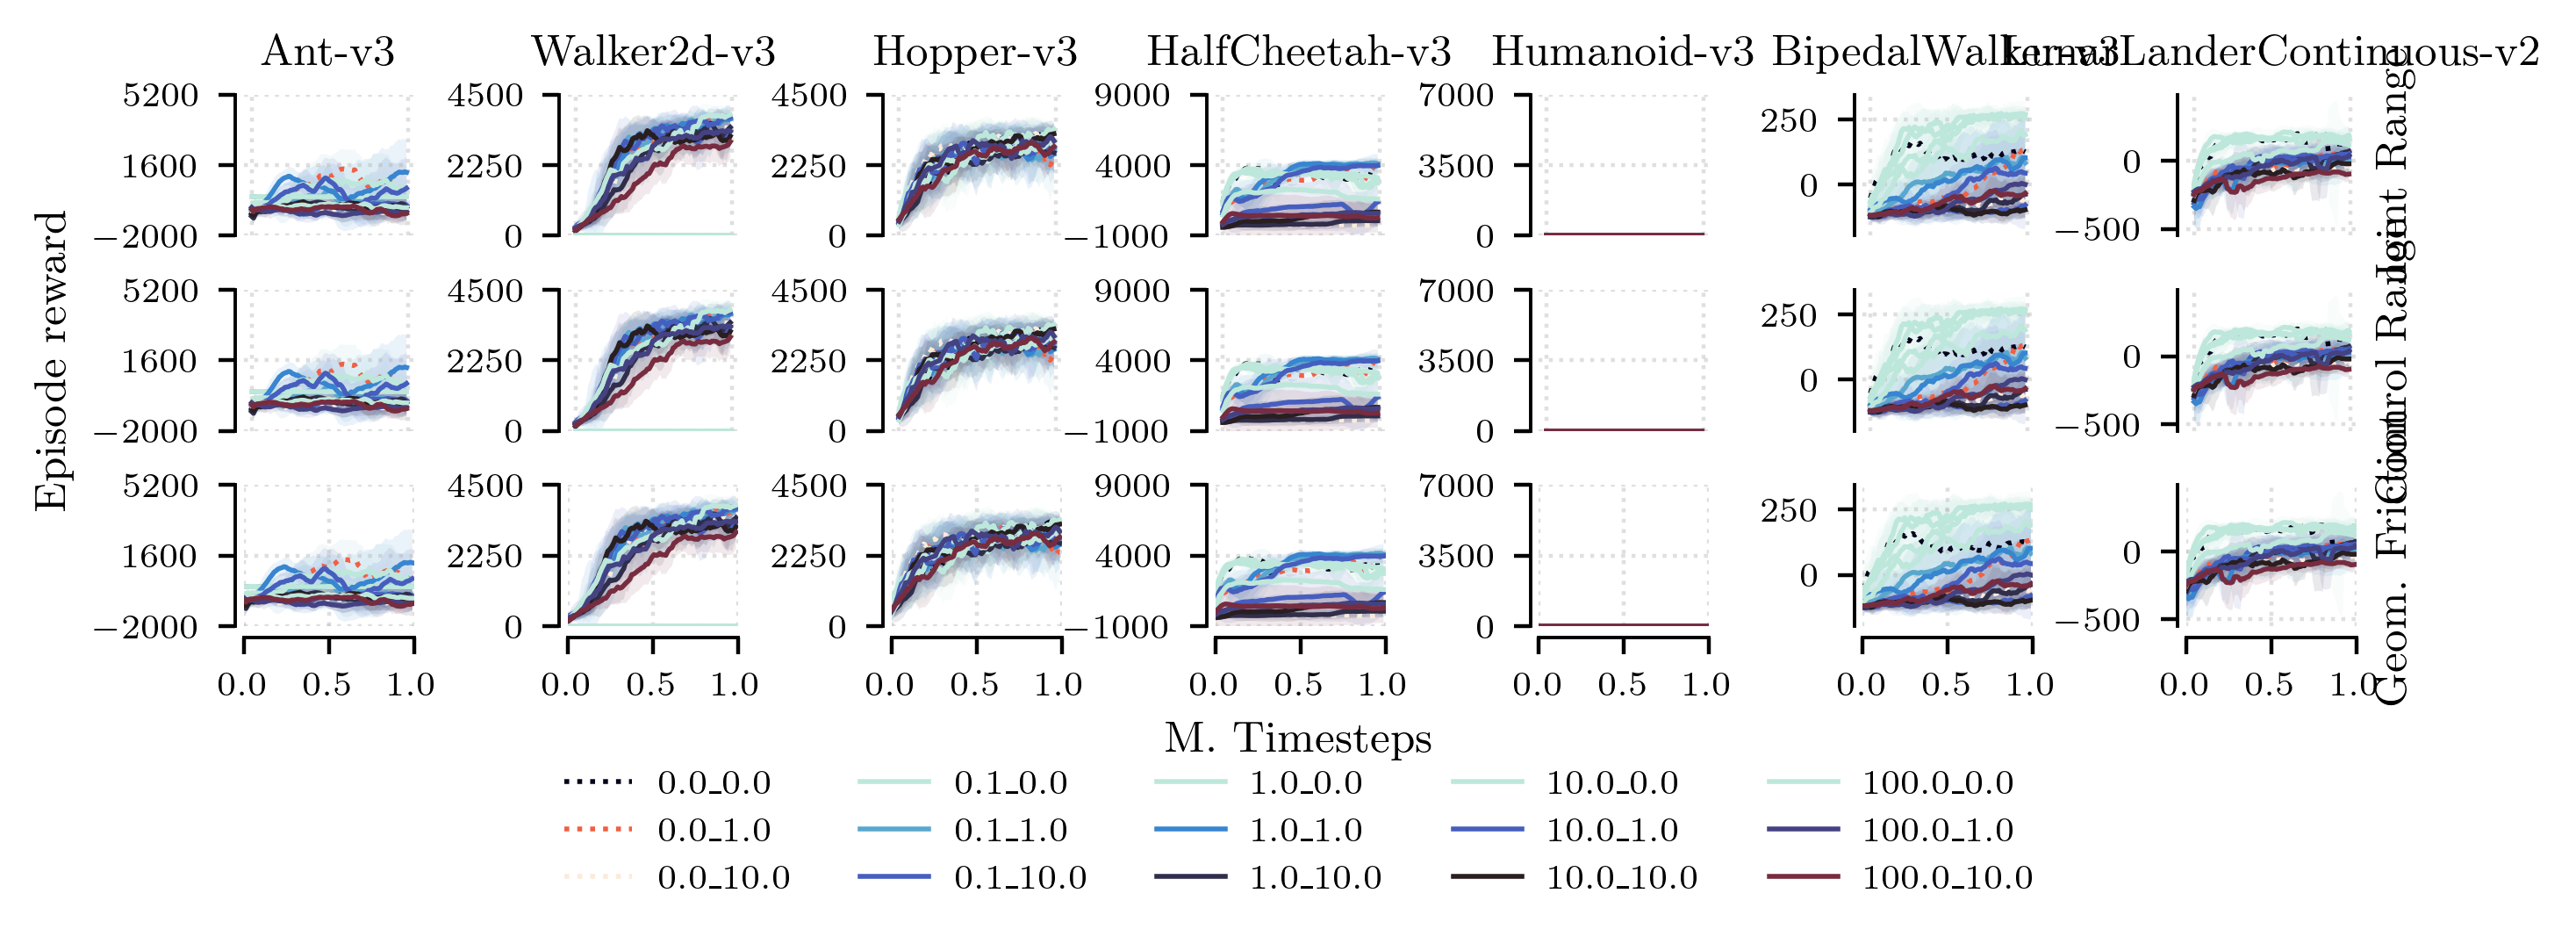

In [11]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3', 'BipedalWalker-v3', 'LunarLanderContinuous-v2']

# TODO: add GAIL and MEIRL
d_airl_jnt, d_airl_jnt_mustd = process_results(envs, results_advtra, 
                                        param_filter_key_list=['use_actions','exp_name'],param_filter_value_list=['True','sac_airl'])


d_mustds = {'airl': d_airl_jnt_mustd, 'gail':d_airl_jnt_mustd, 'meirl':d_airl_jnt_mustd}
irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
cm2 =sns.color_palette("rocket", as_cmap=True)

from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds),len(envs), dpi=400, figsize=[text_width, 2])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")
            for j, env in enumerate(envs):
                # plot gail

                ax[i,j].set_prop_cycle('color', [cm(1.*(l*m+m)/NUM_COLORS) for i in range(NUM_COLORS)])

                ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)
                    
                #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    
                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.4, linestyle=':')
                
                # set env specific limits
                ax[i,0].set_ylim(-2000, 5200)
                ax[i,0].set_yticks([-2000, 1600, 5200])
                ax[i,1].set_ylim(0, 4500)
                ax[i,1].set_yticks([0, 2250, 4500])
                ax[i,2].set_ylim(0, 4500)
                ax[i,2].set_yticks([0, 2250, 4500])            
                ax[i,3].set_ylim(-1000, 9000)
                ax[i,3].set_yticks([-1000, 4000, 9000])                        
                ax[i,4].set_ylim(0, 7000)
                ax[i,4].set_yticks([0, 3500, 7000])                                          
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])

                
                mu,std = v[env][irm_c][lip_c]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if irm_c == 0.0:
                    ax[i,j].plot(x, mu,lw=1, label=f"{irm_c}_{lip_c}", linestyle=':', color=cm2(2.*m/len(lip_coeffs)))
                else:
                    ax[i,j].plot(x, mu,lw=1, label=f"{irm_c}_{lip_c}")#, linestyle=next(linecycler)[-1])

                ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)
                
            ax[2,3].legend(loc='upper center', bbox_to_anchor=(0.5, -0.8), fancybox=False, shadow=False, frameon=False, ncol=5)
            ax[2,3].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            ax[0,-1].set_ylabel("Joint Range", rotation=90)
            ax[1,-1].set_ylabel("Control Range", rotation=90)
            ax[2,-1].set_ylabel("Geom. Friction", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"fig_pert_advtra.pdf", bbox_inches='tight', pad_inches=0.01)

In [121]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']



Computing mu/std
Missing tuple for ('Ant-v3', 515, 0.0, 0.0)
Missing tuple for ('Ant-v3', 234, 0.0, 0.0)
Missing tuple for ('Ant-v3', 894, 0.0, 0.0)
Missing tuple for ('Ant-v3', 322, 0.0, 0.0)
Missing tuple for ('Ant-v3', 72, 0.0, 0.0)
Missing tuple for ('Ant-v3', 515, 0.0, 1.0)
Missing tuple for ('Ant-v3', 234, 0.0, 1.0)
Missing tuple for ('Ant-v3', 894, 0.0, 1.0)
Missing tuple for ('Ant-v3', 322, 0.0, 1.0)
Missing tuple for ('Ant-v3', 72, 0.0, 1.0)
Missing tuple for ('Ant-v3', 515, 0.0, 10.0)
Missing tuple for ('Ant-v3', 234, 0.0, 10.0)
Missing tuple for ('Ant-v3', 894, 0.0, 10.0)
Missing tuple for ('Ant-v3', 322, 0.0, 10.0)
Missing tuple for ('Ant-v3', 72, 0.0, 10.0)
Missing tuple for ('Ant-v3', 515, 0.1, 0.0)
Missing tuple for ('Ant-v3', 234, 0.1, 0.0)
Missing tuple for ('Ant-v3', 894, 0.1, 0.0)
Missing tuple for ('Ant-v3', 322, 0.1, 0.0)
Missing tuple for ('Ant-v3', 72, 0.1, 0.0)
Missing tuple for ('Ant-v3', 515, 0.1, 1.0)
Missing tuple for ('Ant-v3', 234, 0.1, 1.0)
Missing tuple 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Computing mu/std
Missing tuple for ('Ant-v3', 515, 0.0, 0.0)
Missing tuple for ('Ant-v3', 234, 0.0, 0.0)
Missing tuple for ('Ant-v3', 894, 0.0, 0.0)
Missing tuple for ('Ant-v3', 322, 0.0, 0.0)
Missing tuple for ('Ant-v3', 72, 0.0, 0.0)
Missing tuple for ('Ant-v3', 515, 0.0, 1.0)
Missing tuple for ('Ant-v3', 234, 0.0, 1.0)
Missing tuple for ('Ant-v3', 894, 0.0, 1.0)
Missing tuple for ('Ant-v3', 322, 0.0, 1.0)
Missing tuple for ('Ant-v3', 72, 0.0, 1.0)
Missing tuple for ('Ant-v3', 515, 0.0, 10.0)
Missing tuple for ('Ant-v3', 234, 0.0, 10.0)
Missing tuple for ('Ant-v3', 894, 0.0, 10.0)
Missing tuple for ('Ant-v3', 322, 0.0, 10.0)
Missing tuple for ('Ant-v3', 72, 0.0, 10.0)
Missing tuple for ('Ant-v3', 515, 0.1, 0.0)
Missing tuple for ('Ant-v3', 234, 0.1, 0.0)
Missing tuple for ('Ant-v3', 894, 0.1, 0.0)
Missing tuple for ('Ant-v3', 322, 0.1, 0.0)
Missing tuple for ('Ant-v3', 72, 0.1, 0.0)
Missing tuple for ('Ant-v3', 515, 0.1, 1.0)
Missing tuple for ('Ant-v3', 234, 0.1, 1.0)
Missing tuple 

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

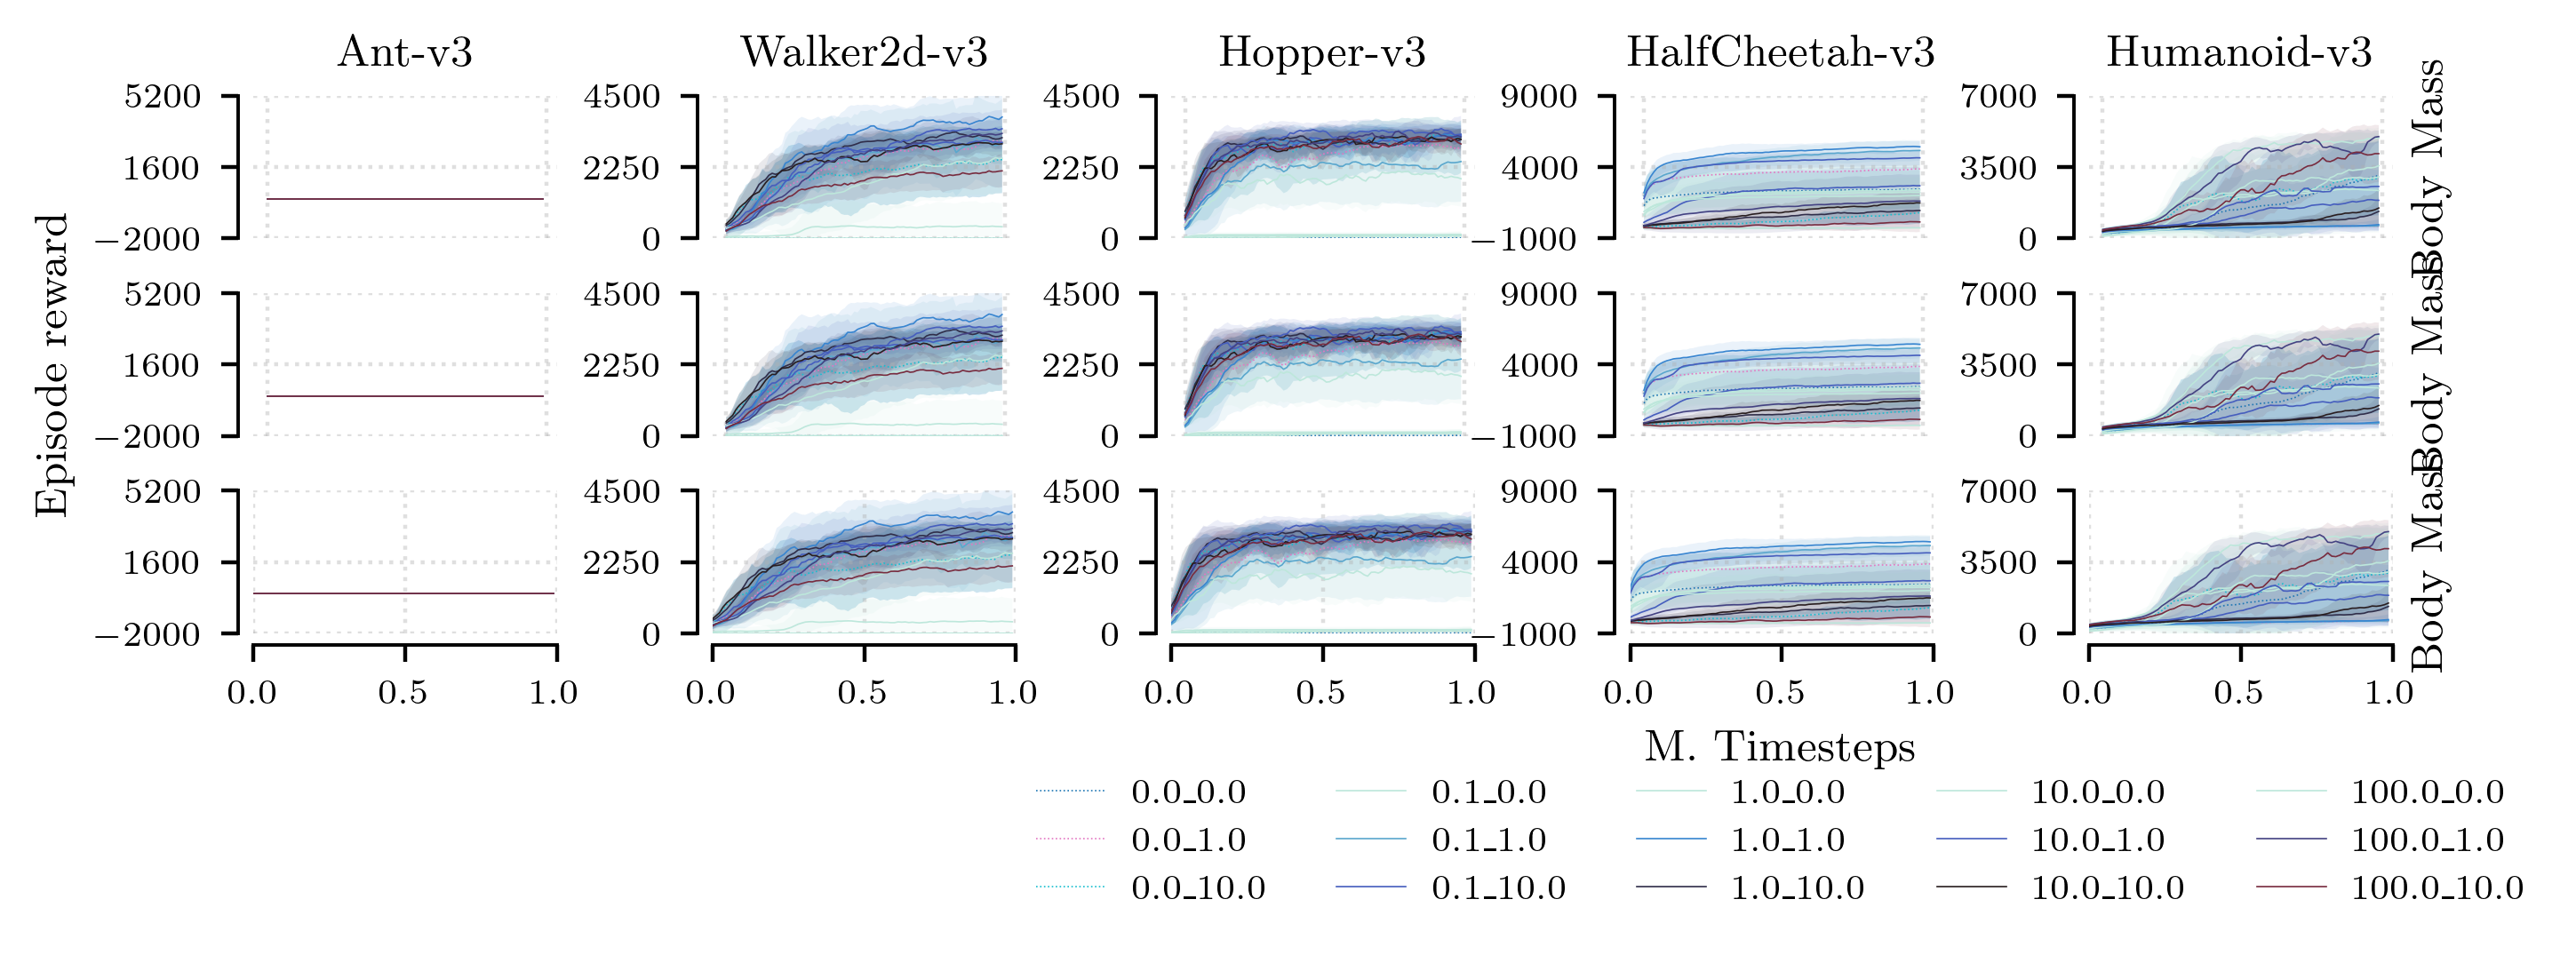

In [12]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

# TODO: add GAIL and MEIRL
d_airl_bm, d_airl_bm_mustd = process_results(envs, results_airl_pert_bm, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_airl','0.1'])

d_mustds = {'airl': d_airl_bm_mustd, 'gail':d_airl_bm_mustd, 'meirl':d_airl_bm_mustd}
irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
cm2 =sns.color_palette("tab10", as_cmap=True)

from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

ref_lw=0.3
text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds),len(envs), dpi=400, figsize=[text_width, 2])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")
            for j, env in enumerate(envs):
                # plot gail

                ax[i,j].set_prop_cycle('color', [cm(1.*(l*m+m)/NUM_COLORS) for i in range(NUM_COLORS)])

                ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)
                    
                #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    
                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.4, linestyle=':')
                
                # set env specific limits
                ax[i,0].set_ylim(-2000, 5200)
                ax[i,0].set_yticks([-2000, 1600, 5200])
                ax[i,1].set_ylim(0, 4500)
                ax[i,1].set_yticks([0, 2250, 4500])
                ax[i,2].set_ylim(0, 4500)
                ax[i,2].set_yticks([0, 2250, 4500])            
                ax[i,3].set_ylim(-1000, 9000)
                ax[i,3].set_yticks([-1000, 4000, 9000])                        
                ax[i,4].set_ylim(0, 7000)
                ax[i,4].set_yticks([0, 3500, 7000])                                          
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])

                
                mu,std = v[env][irm_c][lip_c]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if irm_c == 0.0:
                    ax[i,j].plot(x, mu,lw=ref_lw, label=f"{irm_c}_{lip_c}", linestyle=':', color=cm2(2.*m/len(lip_coeffs)))
                    ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.3)
                else:
                    ax[i,j].plot(x, mu,lw=ref_lw, label=f"{irm_c}_{lip_c}")#, linestyle=next(linecycler)[-1])
                    ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)


                
            ax[2,3].legend(loc='upper center', bbox_to_anchor=(0.5, -0.8), fancybox=False, shadow=False, frameon=False, ncol=5)
            ax[2,3].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            ax[0,-1].set_ylabel("AIRL", rotation=90)
            ax[1,-1].set_ylabel("GAIL", rotation=90)
            ax[2,-1].set_ylabel("MEIRL", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"fig_pert_bm.pdf", bbox_inches='tight', pad_inches=0.01)

Computing mu/std
Missing tuple for ('Ant-v3', 515, 0.0, 0.0)
Missing tuple for ('Ant-v3', 234, 0.0, 0.0)
Missing tuple for ('Ant-v3', 894, 0.0, 0.0)
Missing tuple for ('Ant-v3', 322, 0.0, 0.0)
Missing tuple for ('Ant-v3', 72, 0.0, 0.0)
Missing tuple for ('Ant-v3', 515, 0.1, 0.0)
Missing tuple for ('Ant-v3', 234, 0.1, 0.0)
Missing tuple for ('Ant-v3', 894, 0.1, 0.0)
Missing tuple for ('Ant-v3', 322, 0.1, 0.0)
Missing tuple for ('Ant-v3', 72, 0.1, 0.0)
Incomplete length: sac_airl Ant-v3 894 0.1 10.0 89
Missing tuple for ('Ant-v3', 515, 1.0, 0.0)
Missing tuple for ('Ant-v3', 234, 1.0, 0.0)
Missing tuple for ('Ant-v3', 894, 1.0, 0.0)
Missing tuple for ('Ant-v3', 322, 1.0, 0.0)
Missing tuple for ('Ant-v3', 72, 1.0, 0.0)
Missing tuple for ('Ant-v3', 515, 10.0, 0.0)
Missing tuple for ('Ant-v3', 234, 10.0, 0.0)
Missing tuple for ('Ant-v3', 894, 10.0, 0.0)
Missing tuple for ('Ant-v3', 322, 10.0, 0.0)
Missing tuple for ('Ant-v3', 72, 10.0, 0.0)
Missing tuple for ('Ant-v3', 234, 10.0, 10.0)
Missi

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

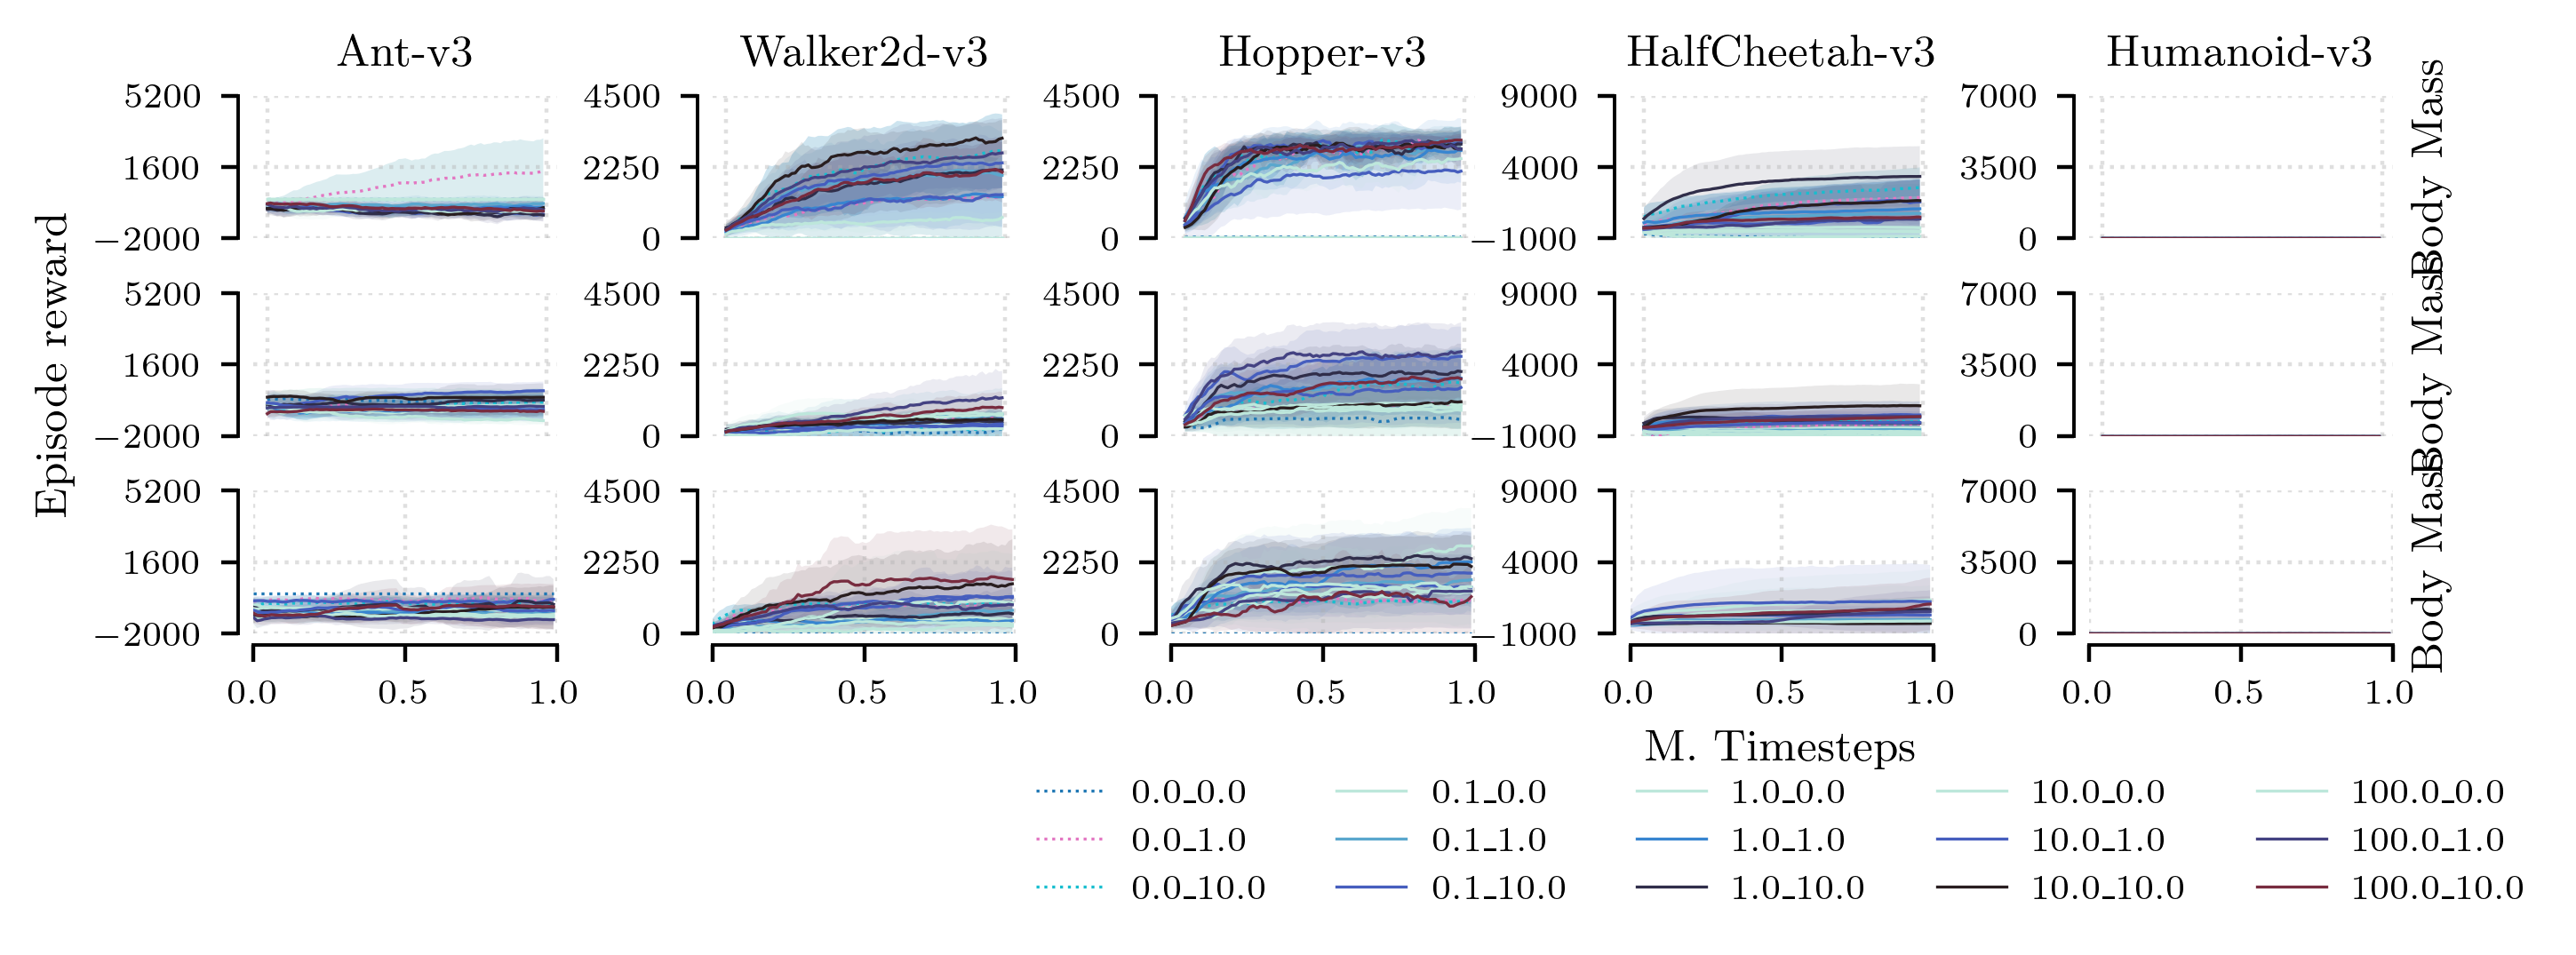

In [15]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

# TODO: add GAIL and MEIRL
# d_airl_bm, d_airl_bm_mustd = process_results(envs, results_airl_pert_bm, 
#                                         param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
#                                         param_filter_value_list=['True','sac_airl','0.1'])

d_airl_cl, d_airl_cl_mustd = process_results(envs, results_clean_load_1, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_airl','0.1'])

d_gail_cl, d_gail_cl_mustd = process_results(envs, results_clean_load_1, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_gail','0.1'])

d_meirl_cl, d_meirl_cl_mustd = process_results(envs, results_clean_load_1, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_meirl','0.1'])

d_mustds = {'airl': d_airl_cl_mustd, 'gail':d_gail_cl_mustd, 'meirl':d_meirl_cl_mustd}
irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
cm2 =sns.color_palette("tab10", as_cmap=True)

from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

ref_lw=0.6
text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds),len(envs), dpi=400, figsize=[text_width, 2])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")
            for j, env in enumerate(envs):
                # plot gail

                ax[i,j].set_prop_cycle('color', [cm(1.*(l*m+m)/NUM_COLORS) for i in range(NUM_COLORS)])

                ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)
                    
                #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    
                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.4, linestyle=':')
                
                # set env specific limits
                ax[i,0].set_ylim(-2000, 5200)
                ax[i,0].set_yticks([-2000, 1600, 5200])
                ax[i,1].set_ylim(0, 4500)
                ax[i,1].set_yticks([0, 2250, 4500])
                ax[i,2].set_ylim(0, 4500)
                ax[i,2].set_yticks([0, 2250, 4500])            
                ax[i,3].set_ylim(-1000, 9000)
                ax[i,3].set_yticks([-1000, 4000, 9000])                        
                ax[i,4].set_ylim(0, 7000)
                ax[i,4].set_yticks([0, 3500, 7000])                                          
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])

                
                mu,std = v[env][irm_c][lip_c]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if irm_c == 0.0:
                    ax[i,j].plot(x, mu,lw=ref_lw, label=f"{irm_c}_{lip_c}", linestyle=':', color=cm2(2.*m/len(lip_coeffs)))
                    ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.3)
                else:
                    ax[i,j].plot(x, mu,lw=ref_lw, label=f"{irm_c}_{lip_c}")#, linestyle=next(linecycler)[-1])
                    ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)


                
            ax[2,3].legend(loc='upper center', bbox_to_anchor=(0.5, -0.8), fancybox=False, shadow=False, frameon=False, ncol=5)
            ax[2,3].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            ax[0,-1].set_ylabel("Body Mass", rotation=90)
            ax[1,-1].set_ylabel("Body Mass", rotation=90)
            ax[2,-1].set_ylabel("Body Mass", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"fig_pert_bm.pdf", bbox_inches='tight', pad_inches=0.01)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


Computing mu/std
Missing tuple for ('Ant-v3', 515, 0.0, 0.0)
Missing tuple for ('Ant-v3', 234, 0.0, 0.0)
Missing tuple for ('Ant-v3', 894, 0.0, 0.0)
Missing tuple for ('Ant-v3', 322, 0.0, 0.0)
Missing tuple for ('Ant-v3', 72, 0.0, 0.0)
Incomplete length: sac_airl Ant-v3 322 0.0 1.0 87
Incomplete length: sac_airl Ant-v3 322 0.0 10.0 80
Missing tuple for ('Ant-v3', 515, 0.1, 0.0)
Missing tuple for ('Ant-v3', 234, 0.1, 0.0)
Missing tuple for ('Ant-v3', 894, 0.1, 0.0)
Missing tuple for ('Ant-v3', 322, 0.1, 0.0)
Missing tuple for ('Ant-v3', 72, 0.1, 0.0)
Missing tuple for ('Ant-v3', 515, 1.0, 0.0)
Missing tuple for ('Ant-v3', 234, 1.0, 0.0)
Missing tuple for ('Ant-v3', 894, 1.0, 0.0)
Missing tuple for ('Ant-v3', 322, 1.0, 0.0)
Missing tuple for ('Ant-v3', 72, 1.0, 0.0)
Missing tuple for ('Ant-v3', 515, 10.0, 0.0)
Missing tuple for ('Ant-v3', 234, 10.0, 0.0)
Missing tuple for ('Ant-v3', 894, 10.0, 0.0)
Missing tuple for ('Ant-v3', 322, 10.0, 0.0)
Missing tuple for ('Ant-v3', 72, 10.0, 0.0)
I

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

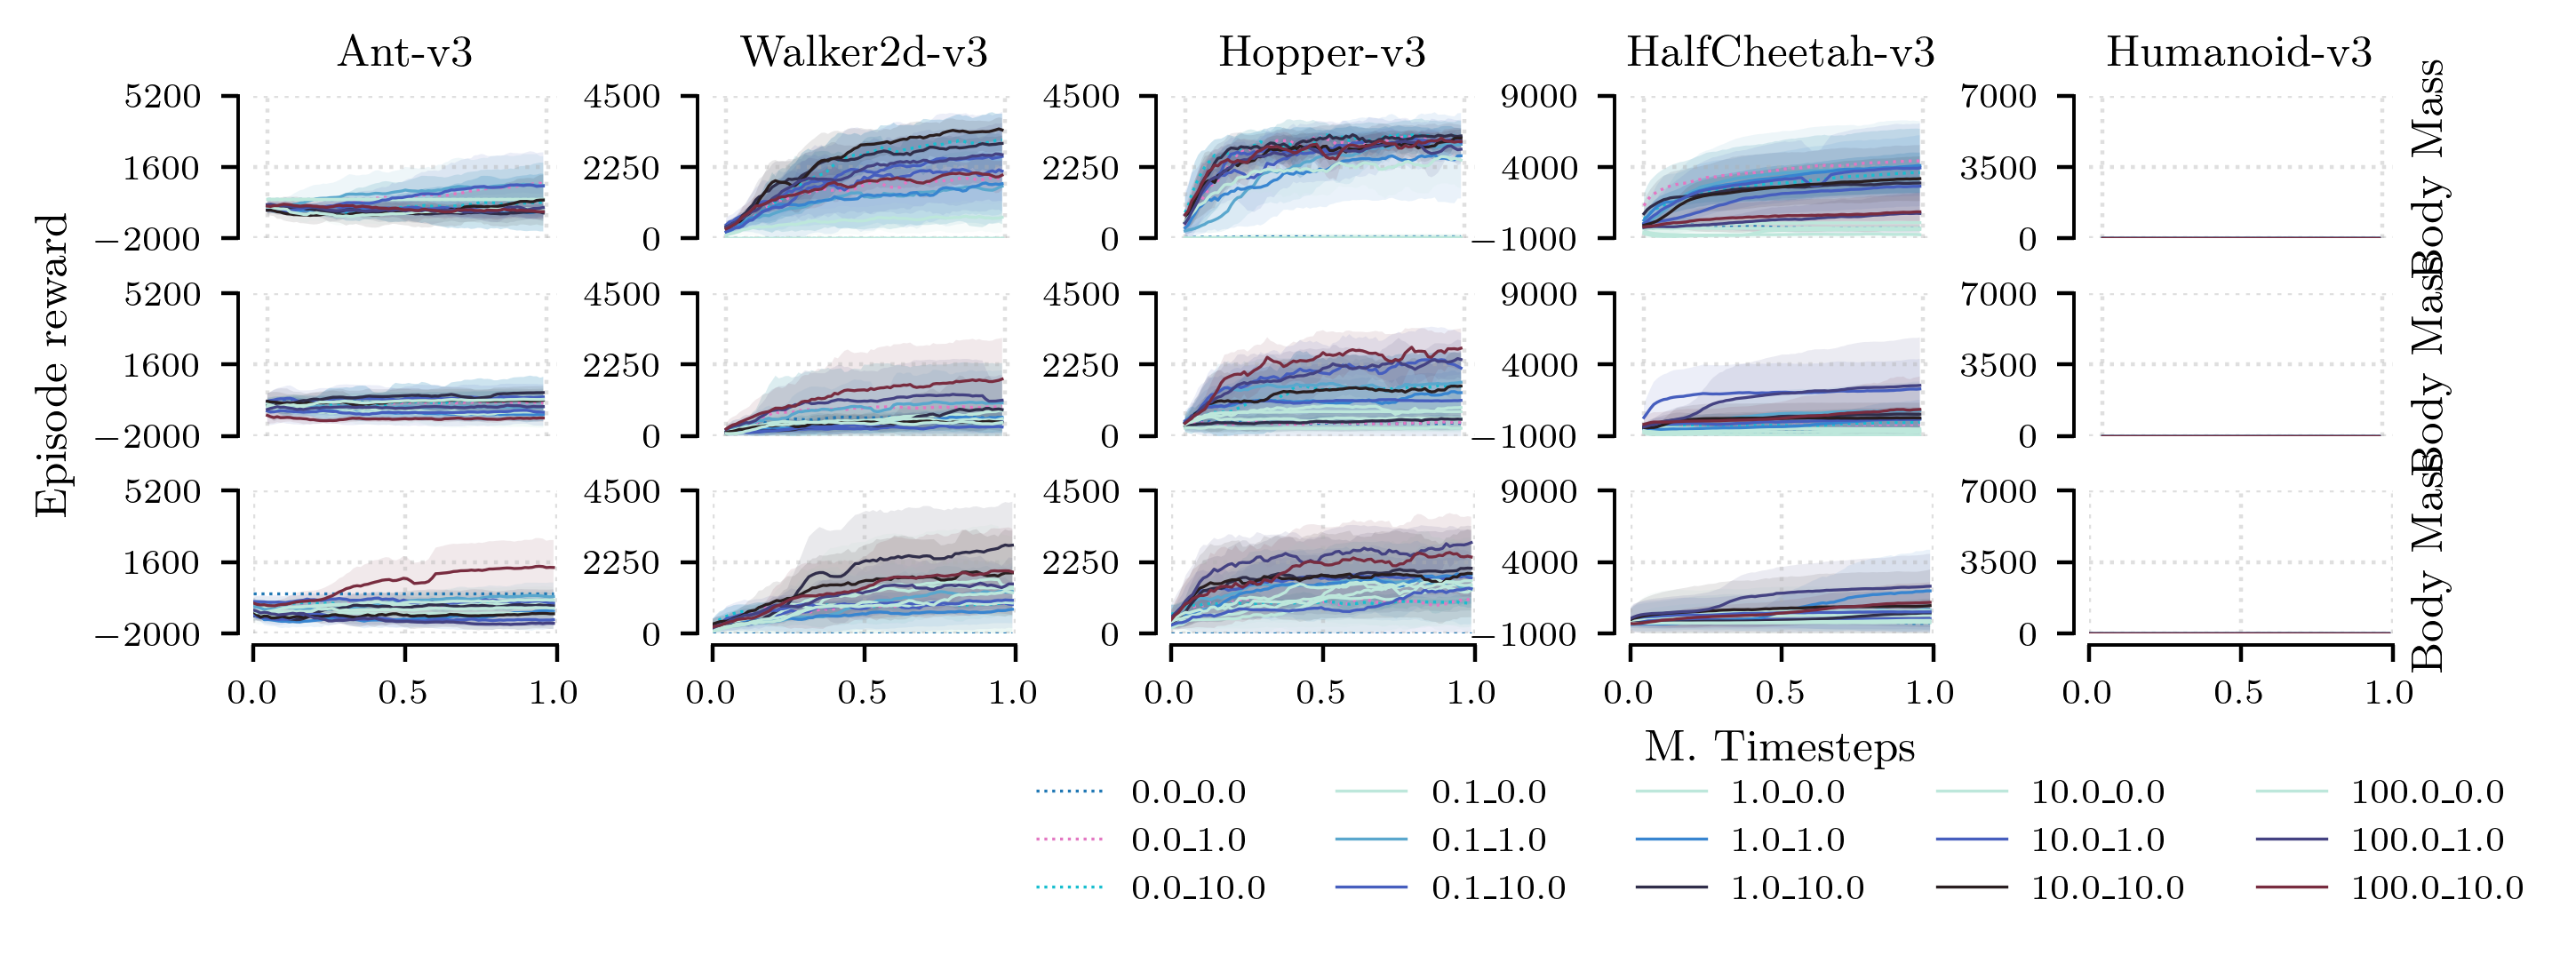

In [16]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3']

# TODO: add GAIL and MEIRL
# d_airl_bm, d_airl_bm_mustd = process_results(envs, results_airl_pert_bm, 
#                                         param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
#                                         param_filter_value_list=['True','sac_airl','0.1'])

d_airl_cl, d_airl_cl_mustd = process_results(envs, results_clean_load_2, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_airl','0.1'])

d_gail_cl, d_gail_cl_mustd = process_results(envs, results_clean_load_2, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_gail','0.1'])

d_meirl_cl, d_meirl_cl_mustd = process_results(envs, results_clean_load_2, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_meirl','0.1'])

d_mustds = {'airl': d_airl_cl_mustd, 'gail':d_gail_cl_mustd, 'meirl':d_meirl_cl_mustd}
irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
cm2 =sns.color_palette("tab10", as_cmap=True)

from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

ref_lw=0.6
text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds),len(envs), dpi=400, figsize=[text_width, 2])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")
            for j, env in enumerate(envs):
                # plot gail

                ax[i,j].set_prop_cycle('color', [cm(1.*(l*m+m)/NUM_COLORS) for i in range(NUM_COLORS)])

                ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)
                    
                #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    
                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.4, linestyle=':')
                
                # set env specific limits
                ax[i,0].set_ylim(-2000, 5200)
                ax[i,0].set_yticks([-2000, 1600, 5200])
                ax[i,1].set_ylim(0, 4500)
                ax[i,1].set_yticks([0, 2250, 4500])
                ax[i,2].set_ylim(0, 4500)
                ax[i,2].set_yticks([0, 2250, 4500])            
                ax[i,3].set_ylim(-1000, 9000)
                ax[i,3].set_yticks([-1000, 4000, 9000])                        
                ax[i,4].set_ylim(0, 7000)
                ax[i,4].set_yticks([0, 3500, 7000])                                          
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])

                
                mu,std = v[env][irm_c][lip_c]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if irm_c == 0.0:
                    ax[i,j].plot(x, mu,lw=ref_lw, label=f"{irm_c}_{lip_c}", linestyle=':', color=cm2(2.*m/len(lip_coeffs)))
                    ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.3)
                else:
                    ax[i,j].plot(x, mu,lw=ref_lw, label=f"{irm_c}_{lip_c}")#, linestyle=next(linecycler)[-1])
                    ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)


                
            ax[2,3].legend(loc='upper center', bbox_to_anchor=(0.5, -0.8), fancybox=False, shadow=False, frameon=False, ncol=5)
            ax[2,3].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            ax[0,-1].set_ylabel("Body Mass", rotation=90)
            ax[1,-1].set_ylabel("Body Mass", rotation=90)
            ax[2,-1].set_ylabel("Body Mass", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"fig_pert_bm.pdf", bbox_inches='tight', pad_inches=0.01)

Computing mu/std
Incomplete length: sac_airl Ant-v3 515 0.0 0.0 60
Incomplete length: sac_airl Ant-v3 234 0.0 0.0 67
Incomplete length: sac_airl Ant-v3 894 0.0 0.0 61
Incomplete length: sac_airl Ant-v3 322 0.0 0.0 62
Incomplete length: sac_airl Ant-v3 72 0.0 0.0 66
Incomplete length: sac_airl Ant-v3 234 0.1 0.0 86
Incomplete length: sac_airl Ant-v3 322 0.1 0.0 73
Incomplete length: sac_airl Ant-v3 72 0.1 0.0 71
Incomplete length: sac_airl Ant-v3 515 1.0 0.0 68
Incomplete length: sac_airl Ant-v3 234 1.0 0.0 61
Incomplete length: sac_airl Ant-v3 322 1.0 0.0 53
Incomplete length: sac_airl Ant-v3 72 1.0 0.0 82
Incomplete length: sac_airl Ant-v3 515 10.0 0.0 65
Incomplete length: sac_airl Ant-v3 322 10.0 0.0 85
Incomplete length: sac_airl Walker2d-v3 515 0.0 0.0 47
Incomplete length: sac_airl Walker2d-v3 234 0.0 0.0 44
Incomplete length: sac_airl Walker2d-v3 894 0.0 0.0 49
Incomplete length: sac_airl Walker2d-v3 322 0.0 0.0 45
Incomplete length: sac_airl Walker2d-v3 72 0.0 0.0 44
Incomplete

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

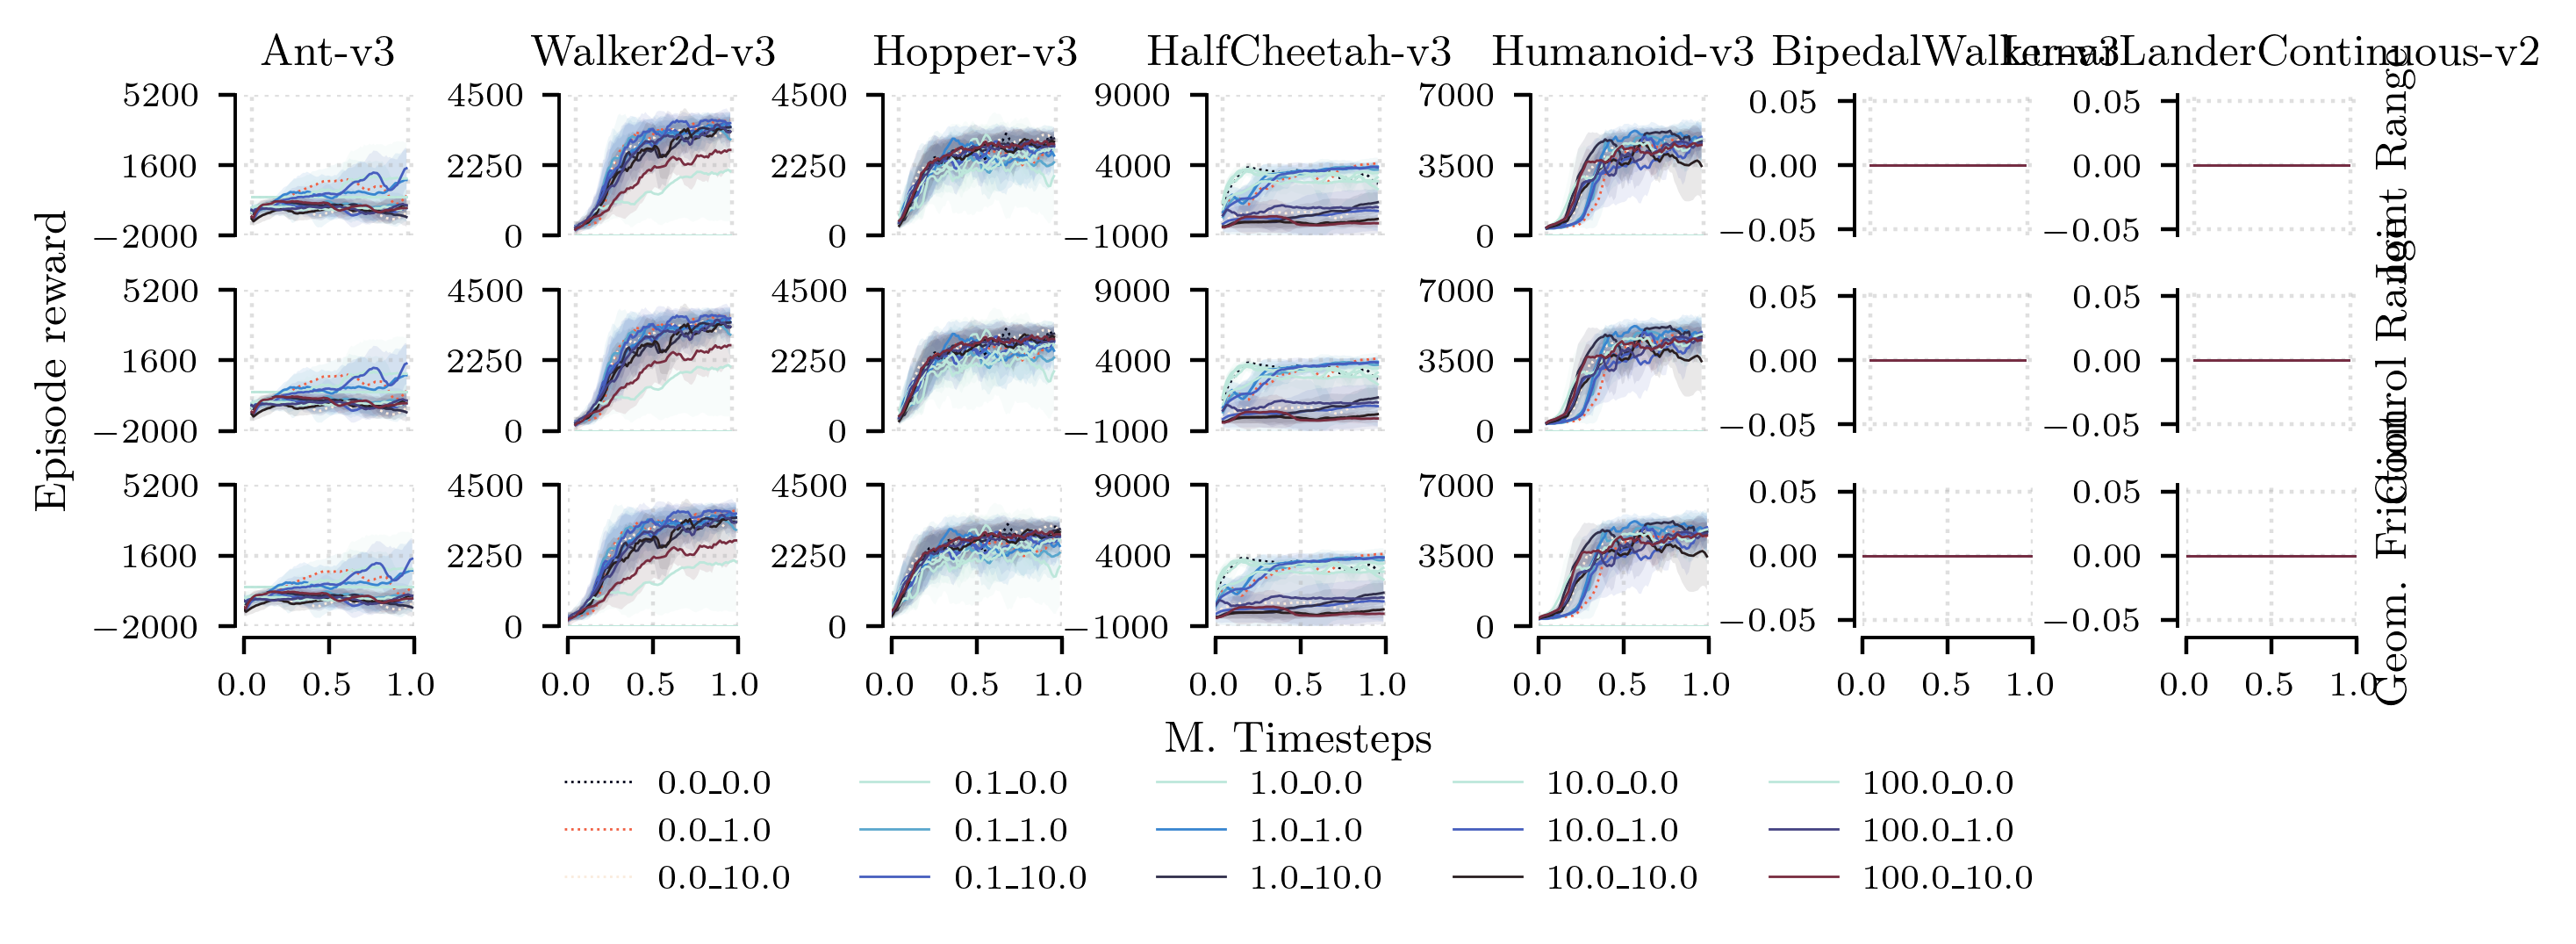

In [18]:
envs = ['Ant-v3', 'Walker2d-v3', 'Hopper-v3', 'HalfCheetah-v3', 'Humanoid-v3', 'BipedalWalker-v3', 'LunarLanderContinuous-v2']

# TODO: add GAIL and MEIRL
d_airl_advtra_pert, d_airl_advtra_pert_mustd = process_results(envs, results_advtra_pert_airl, 
                                        param_filter_key_list=['use_actions','exp_name'],param_filter_value_list=['True','sac_airl'])


d_mustds = {'airl': d_airl_advtra_pert_mustd, 'gail':d_airl_advtra_pert_mustd, 'meirl':d_airl_advtra_pert_mustd}
irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
cm2 =sns.color_palette("rocket", as_cmap=True)

from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds),len(envs), dpi=400, figsize=[text_width, 2])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")
            for j, env in enumerate(envs):
                # plot gail

                ax[i,j].set_prop_cycle('color', [cm(1.*(l*m+m)/NUM_COLORS) for i in range(NUM_COLORS)])

                ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)
                    
                #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    
                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.4, linestyle=':')
                
                # set env specific limits
                ax[i,0].set_ylim(-2000, 5200)
                ax[i,0].set_yticks([-2000, 1600, 5200])
                ax[i,1].set_ylim(0, 4500)
                ax[i,1].set_yticks([0, 2250, 4500])
                ax[i,2].set_ylim(0, 4500)
                ax[i,2].set_yticks([0, 2250, 4500])            
                ax[i,3].set_ylim(-1000, 9000)
                ax[i,3].set_yticks([-1000, 4000, 9000])                        
                ax[i,4].set_ylim(0, 7000)
                ax[i,4].set_yticks([0, 3500, 7000])                                          
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])

                
                mu,std = v[env][irm_c][lip_c]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if irm_c == 0.0:
                    ax[i,j].plot(x, mu,lw=.5, label=f"{irm_c}_{lip_c}", linestyle=':', color=cm2(2.*m/len(lip_coeffs)))
                else:
                    ax[i,j].plot(x, mu,lw=.5, label=f"{irm_c}_{lip_c}")#, linestyle=next(linecycler)[-1])

                ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)
                
            ax[2,3].legend(loc='upper center', bbox_to_anchor=(0.5, -0.8), fancybox=False, shadow=False, frameon=False, ncol=5)
            ax[2,3].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            ax[0,-1].yaxis.set_label_position("right")
            ax[1,-1].yaxis.set_label_position("right")
            ax[2,-1].yaxis.set_label_position("right") 
            ax[0,-1].set_ylabel("Joint Range", rotation=90)
            ax[1,-1].set_ylabel("Control Range", rotation=90)
            ax[2,-1].set_ylabel("Geom. Friction", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"fig_pert_advtra.pdf", bbox_inches='tight', pad_inches=0.01)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

../runs/IRL_IRM/2001_ll_pert/20240120_224835_100373_LunarLanderContinuous-v2__sac_gail_seed_515_irm10.0_lip1.0_ua__seed_515__env_id__LunarLanderContinuous-v2___env_kwargs_[_enable_wind___wind_power_]__env_kwargs_values_[1.0_10.0]__diverse_demos__dir
['enable_wind'
[1.0
../runs/IRL_IRM/2001_ll_pert/20240120_224828_681653_LunarLanderContinuous-v2__sac_meirl_seed_515_irm1.0_lip1.0_ua__seed_515__env_id__LunarLanderContinuous-v2___env_kwargs_[_gravity_]__env_kwargs_values_[-12.0]__diverse_demos__dirty___irm_coeff_1.0__
['gravity']
[-12.0]
../runs/IRL_IRM/2001_ll_pert/20240120_225237_234098_LunarLanderContinuous-v2__sac_airl_seed_894_irm0.1_lip1.0_ua__seed_894__env_id__LunarLanderContinuous-v2___env_kwargs_[_gravity_]__env_kwargs_values_[-11.5]__diverse_demos__dirty___irm_coeff_0.1__l
['gravity']
[-11.5]
../runs/IRL_IRM/2001_ll_pert/20240120_225246_542522_LunarLanderContinuous-v2__sac_airl_seed_72_irm100.0_lip1.0_ua__seed_72__env_id__LunarLanderContinuous-v2___env_kwargs_[_gravity_]__env_kwa

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that 

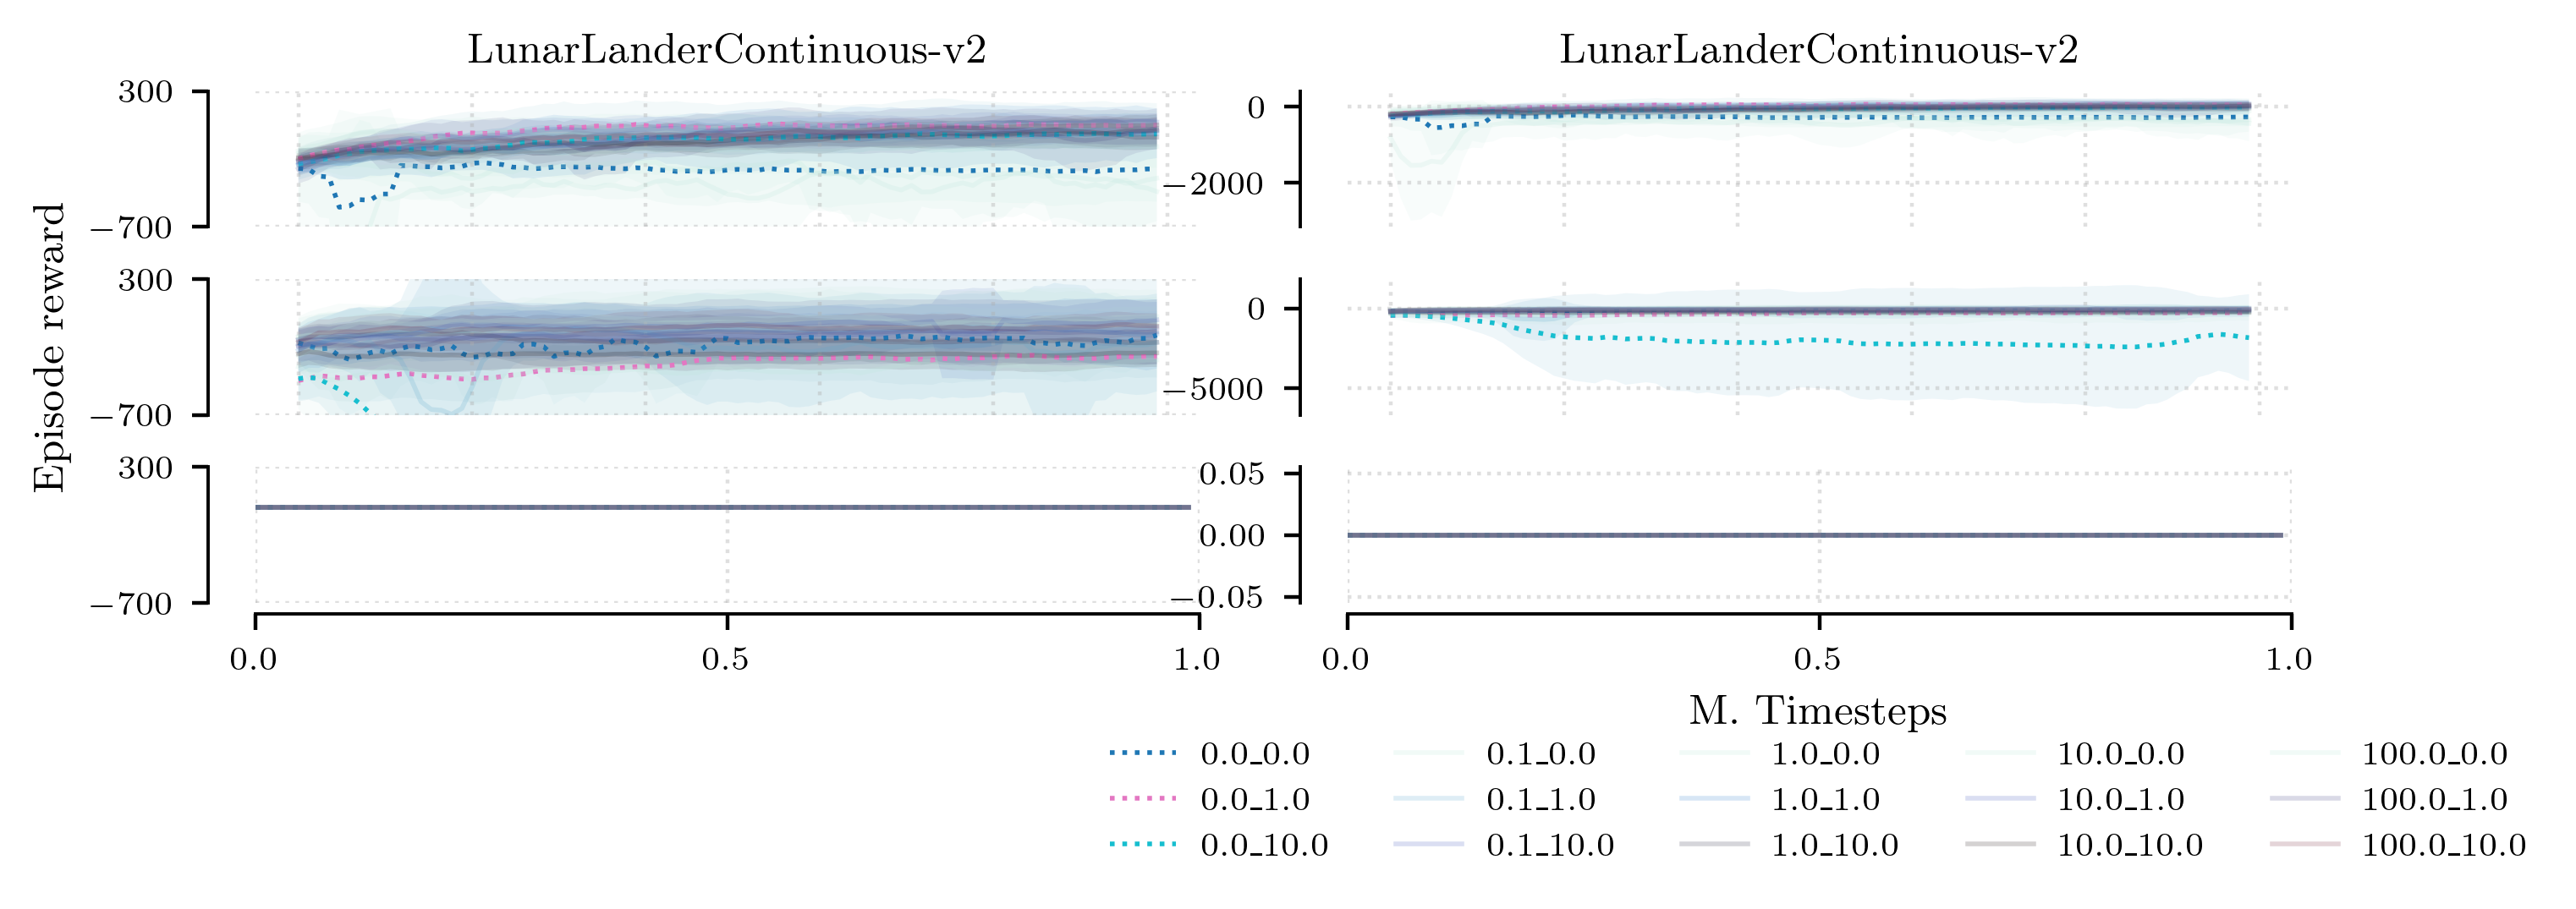

In [152]:
envs = ['LunarLanderContinuous-v2','LunarLanderContinuous-v2']

# TODO: add GAIL and MEIRL
d_airl_pert_ll, d_airl_pert_ll_mustd = process_results(envs, results_ll_pert, 
                                        param_filter_key_list=['use_actions','exp_name','env_kwargs', 'env_kwargs_values'],
                                        param_filter_value_list=['True','sac_airl',"['gravity']", '[-11.5]'], print_files=True)
d_airl_pert_ll_2, d_airl_pert_ll_2_mustd = process_results(envs, results_ll_pert, 
                                        param_filter_key_list=['use_actions','exp_name','env_kwargs', 'env_kwargs_values'],
                                        param_filter_value_list=['True','sac_meirl',"['gravity']", '[-8.0]'], print_files=True)
d_airl_pert_ll_3, d_airl_pert_ll_3_mustd = process_results(envs, results_ll_pert, 
                                        param_filter_key_list=['use_actions','exp_name','env_kwargs', 'env_kwargs_values'],
                                        param_filter_value_list=['True','sac_airl',"['enable_wind'", '[1.0'], print_files=True)

d_gail_pert_ll, d_gail_pert_ll_mustd = process_results(envs, results_ll_pert, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_gail','0.1'])
d_meirl_pert_ll, d_meirl_pert_ll_mustd = process_results(envs, results_ll_pert, 
                                        param_filter_key_list=['use_actions','exp_name','perturb_dynamics'],
                                        param_filter_value_list=['True','sac_meirl','0.1'])
                                        
d_mustds = {'airl': d_airl_pert_ll_mustd, 'gail':d_airl_pert_ll_2_mustd, 'meirl':d_meirl_pert_ll_mustd}
irm_coeffs=[0.0, 0.1, 1.0, 10.0, 100.0]
lip_coeffs=[0.0, 1.0, 10.0]

###
env_exp = [5150, 4050, 3607, 8900, 6249]

n_demos = [1,4,10]
sss = [1]
subsample_plot = 1
NUM_COLORS = len(irm_coeffs)*len(lip_coeffs)
#cm = plt.get_cmap('gist_rainbow')
#cm = sns.color_palette("tab10", as_cmap=True)
cm =sns.color_palette("icefire", as_cmap=True)
cm2 =sns.color_palette("tab10", as_cmap=True)

from itertools import cycle

linestyle_tuple = [
     ('solid', 'solid'), 
     ('dashdot', 'dashdot'),
     ('dotted',                (0, (1, 1))),
     ('densely dotted',        (0, (1, 1))),
     ('densely dashed',        (0, (5, 1))),
     ('dashdotted',            (0, (3, 5, 1, 5))),
     ('densely dashdotted',    (0, (3, 1, 1, 1))),
     ('dashdotdotted',         (0, (3, 5, 1, 5, 1, 5))),
     ('densely dashdotdotted', (0, (3, 1, 1, 1, 1, 1)))]

linecycler = cycle(linestyle_tuple[:NUM_COLORS])

text_width = 6.6
text_height = 9.0
fig,ax = plt.subplots(len(d_mustds),len(envs), dpi=400, figsize=[text_width, 2])
#fig.tight_layout(w_pad=1, h_pad=1)
fig.tight_layout(h_pad=-0.5,w_pad=1)

for i, (k,v) in enumerate(d_mustds.items()):       
    for l, irm_c in enumerate(irm_coeffs):
        for m, lip_c in enumerate(lip_coeffs):
        #fig, ax = plt.subplots(1,5,figsize=(24,4))
        #fig.suptitle(f"ss:{ss}_nd:{n_d}")
            for j, env in enumerate(envs):
                # plot gail

                ax[i,j].set_prop_cycle('color', [cm(1.*(l*m+m)/NUM_COLORS) for i in range(NUM_COLORS)])

                ax[0,j].set_title(env)
                #if j > 0:
                    #remove_yticks(ax[i,j])
                    #ax[i,j].spines[['left']].set_visible(False)
                    
                #ax[i,j].axhline(env_exp[j], xmin=0, xmax=1, c='m', lw=1, linestyle='dotted', alpha=0.4)

                if i < 2:
                    ax[i,j].spines[['top', 'bottom', 'right']].set_visible(False)
                    remove_xticks(ax[i,j])
                    
                ax[i,j].spines[['top' , 'right']].set_visible(False)
                ax[i,j].spines['left'].set_position(('axes', -0.05))
                ax[i,j].spines['bottom'].set_position(('axes', -0.08))

                ax[i,j].grid(alpha=0.4, linestyle=':')
                
                # set env specific limits
                ax[i,0].set_ylim(-700, 300)
                ax[i,0].set_yticks([-700, 300])
                ax[2,j].set_xlim(0,1.0)
                ax[2,j].set_xticks([0, 0.5, 1.0])

                
                mu,std = v[env][irm_c][lip_c]
                mu,std = smooth_mu_std(mu,std)
                mu = mu[::subsample_plot]
                std = std[::subsample_plot]

                x = np.arange(len(mu))/len(mu)
                if irm_c == 0.0:
                    ax[i,j].plot(x, mu,lw=1, label=f"{irm_c}_{lip_c}", linestyle=':', color=cm2(2.*m/len(lip_coeffs)))
                else:
                    ax[i,j].plot(x, mu,lw=1, label=f"{irm_c}_{lip_c}", alpha=0.2)#, linestyle=next(linecycler)[-1])

                ax[i,j].fill_between(x,mu+std, mu-std, alpha=0.1)
                
            ax[2,-1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.8), fancybox=False, shadow=False, frameon=False, ncol=5)
            ax[2,-1].set_xlabel('M. Timesteps')
            ax[1,0].set_ylabel('Episode reward')
            # ax[0,-1].yaxis.set_label_position("right")
            # ax[1,-1].yaxis.set_label_position("right")
            # ax[2,-1].yaxis.set_label_position("right") 
            # ax[0,-1].set_ylabel("Joint Range", rotation=90)
            # ax[1,-1].set_ylabel("Control Range", rotation=90)
            # ax[2,-1].set_ylabel("Geom. Friction", rotation=90)

#fig.tight_layout(w_pad=1, h_pad=1)
#plt.tight_layout()
fig.savefig(f"fig_pert_bm.pdf", bbox_inches='tight', pad_inches=0.01)